# MorphoNup — SHAP and explainability

Explains the **saved** MorphoNup models (no training) on their own outer test rows; the background comes from each fold's training rows.

Feature attribution only (how much each input contributes); motif and sequence-pattern analyses are a separate study.

* **Group Shapley values** (exact, all 2^11 coalitions of sequence, k-mers, MGW, Roll, EP, PLS 1-6), read at three resolutions of the same game: input modality (Sequence, k-mers, Shape), shape tracks (PLS block as one), shape channels. At each level they sum to the prediction minus the background mean; levels are not additive across levels. Also pairwise interactions, results by prediction outcome, summary (beeswarm) and dependence plots.
* **Integrated gradients**: where along the 147 bp the sequence and each shape channel act, and a cross-check of the modality ranking against the Shapley values.
* **PLS loadings** to read the PLS players in terms of the 7 original shape tracks.
* Every rebuilt model is first checked against its saved test predictions.

These describe what the model uses; they are associations, not causal claims.

In [1]:
DATASET = "DatasetNup_1/Homo_sapiens"
K_FOLDS = 5
SEED = 151000
FOLDS = None                 # None = every outer fold
N_TARGETS = 200              # explained test sequences per fold (half per class)
N_BACKGROUND = 50            # background sequences per fold (training rows)
STEPS = 32                   # integrated-gradients steps
RUN_MODE = "results_only"    # "background" | "inline" | "results_only"
ALLOW_BUSY_GPU = False

In [2]:
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
_null, _err = os.open(os.devnull, os.O_WRONLY), os.dup(2)
os.dup2(_null, 2)                                    # TensorFlow's CUDA start-up lines go to C-level stderr
try:
    import tensorflow  # noqa: F401
finally:
    os.dup2(_err, 2)
    os.close(_null)
    os.close(_err)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "morphonup" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display

from morphonup import config, figures, jobs
from morphonup.cv import run_dir

pd.set_option("display.width", 200, "display.max_columns", 40)


def show(path, width=900):
    """Display a saved figure with its caption (from the folder's figure_catalog.csv)."""
    path = Path(path)
    if not path.exists():
        print("missing:", path.relative_to(ROOT))
        return
    cat = path.parent / "figure_catalog.csv"
    caption = pd.read_csv(cat).set_index("png").suggested_caption.get(path.name, "") if cat.exists() else ""
    display(Markdown(f"**{path.stem}** — `{path.relative_to(ROOT)}`  \n{caption}"))
    display(Image(filename=str(path), width=width))
OUT = run_dir(DATASET, K_FOLDS) / "explain" / f"seed_{SEED}"
models = sorted(run_dir(DATASET, K_FOLDS).glob(f"seed_{SEED}/fold_*/refit/best.weights.h5"))
print(f"saved MorphoNup models for seed {SEED}: {len(models)} of {K_FOLDS} folds")
print("explained folds so far:", sorted(p.parent.name for p in OUT.glob("fold_*/done.json")) or "none")
gpu, procs = jobs.gpu_status()
print("GPU:", gpu, "| processes:", procs or "none")

saved MorphoNup models for seed 151000: 5 of 5 folds
explained folds so far: ['fold_01', 'fold_02', 'fold_03', 'fold_04', 'fold_05']
GPU: NVIDIA GeForce RTX 4070 Ti, 0 %, 1 MiB, 12282 MiB | processes: none


## Run

In [3]:
if RUN_MODE == "background":
    LOG = jobs.launch_explain(DATASET, K_FOLDS, SEED, FOLDS, N_TARGETS, N_BACKGROUND, STEPS,
                              allow_busy_gpu=ALLOW_BUSY_GPU)
    print("launched; log:", LOG.relative_to(ROOT))
elif RUN_MODE == "inline":
    gpu, procs = jobs.gpu_status()
    if procs and not ALLOW_BUSY_GPU:
        raise RuntimeError("GPU in use: " + "; ".join(procs))
    from morphonup.data import Dataset
    from morphonup.explain import explain
    explain(Dataset(config.dataset_folder(DATASET)), run_dir(DATASET, K_FOLDS), K_FOLDS, SEED, FOLDS,
            n_targets=N_TARGETS, n_background=N_BACKGROUND, steps=STEPS)
else:
    print("results_only: nothing started")
print(jobs.tail(jobs.log_path(DATASET, K_FOLDS, [SEED], kind="explain")))

results_only: nothing started
	 [[{{node MorphoNup_C9_1/motif_statistics_1/strided_slice_60}}]]
Hint: If you want to see a list of allocated tensors when OOM happens, add report_tensor_allocations_upon_oom to RunOptions for current allocation info. This isn't available when running in Eager mode.
 [Op:__inference_<lambda>_101685]
# exit 1 : explain DatasetNup_1/Homo_sapiens k5 seed 151000
# 2026-11-07T02:34:36+08:00 queue finished
# 2026-11-07T02:36:41+08:00 relaunch after GPU out-of-memory (batch 4096 > 4 GB cap): coalition_values now batch 1024, halved on OOM; tests/check_explain.py PASS
# launched 2026-11-07T02:36:42: 1 command(s)
explain fold 1: 200 targets, 50 background, 2048 coalitions in 1385s, IG 11s; rebuilt model |Δp| 3.0e-08; additivity 1.2e-15; IG completeness median 1.6e-03
explain fold 2: 200 targets, 50 background, 2048 coalitions in 1406s, IG 10s; rebuilt model |Δp| 3.0e-08; additivity 8.9e-16; IG completeness median 1.0e-03
explain fold 3: 200 targets, 50 background, 

## Results

In [4]:
from morphonup.explain import explain_figures
explain_figures(OUT) if OUT.exists() else None
audit = OUT / "audit.json"
if audit.exists():
    import json
    folds = json.loads(audit.read_text())["folds"]
    display(pd.DataFrame(folds).T[["n_targets", "n_background", "rebuilt_vs_saved_max_abs_probability_difference",
                                   "shapley_additivity_max_error", "ig_completeness_median_abs_error",
                                   "seconds_shapley", "seconds_integrated_gradients"]])
    table = OUT / "shap_table.md"
    print(table.read_text() if table.exists() else "")
else:
    print("no explanation yet")

,n_targets,n_background,rebuilt_vs_saved_max_abs_probability_difference,shapley_additivity_max_error,ig_completeness_median_abs_error,seconds_shapley,seconds_integrated_gradients
1,200,50,0.0,"{'modality': 1.1102230246251565e-16, 'tracks':...",0.001605,1384.9,10.9
2,200,50,0.0,"{'modality': 1.1102230246251565e-16, 'tracks':...",0.001005,1406.4,10.1
3,200,50,0.0,"{'modality': 1.1102230246251565e-16, 'tracks':...",0.001146,1363.9,10.2
4,200,50,0.0,"{'modality': 1.1102230246251565e-16, 'tracks':...",0.001163,1353.6,10.2
5,200,50,0.0,"{'modality': 1.1102230246251565e-16, 'tracks':...",0.001581,1381.8,10.1


| Level | Player | Mean |SHAP| | Share (%) | Mean SHAP, nucleosome | Mean SHAP, linker |
|---|---|---|---|---|---|
| Input modality | Sequence | 0.2201 ± 0.0138 | 55.6 | +0.1883 | -0.1808 |
| Input modality | k-mers | 0.1313 ± 0.0152 | 33.2 | +0.1071 | -0.1001 |
| Input modality | Shape | 0.0445 ± 0.0053 | 11.2 | +0.0364 | -0.0332 |
| Shape tracks (PLS block as one) | Sequence | 0.2207 ± 0.0137 | 55.0 | +0.1886 | -0.1813 |
| Shape tracks (PLS block as one) | k-mers | 0.1320 ± 0.0147 | 32.9 | +0.1077 | -0.1007 |
| Shape tracks (PLS block as one) | EP | 0.0154 ± 0.0057 | 3.8 | +0.0120 | -0.0108 |
| Shape tracks (PLS block as one) | PLS block | 0.0144 ± 0.0049 | 3.6 | +0.0106 | -0.0103 |
| Shape tracks (PLS block as one) | MGW | 0.0129 ± 0.0067 | 3.2 | +0.0096 | -0.0091 |
| Shape tracks (PLS block as one) | Roll | 0.0062 ± 0.0017 | 1.5 | +0.0032 | -0.0019 |
| Shape channels | Sequence | 0.2211 ± 0.0133 | 54.1 | +0.1889 | -0.1818 |
| Shape channels | k-mers | 0.1322 ± 0.0149 | 32.3 | +0.10

**shap_overview** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_overview.png`  
Group Shapley importance at three resolutions of the same game (1000 held-out test sequences, 5 outer fold(s)): (a) input modality, (b) shape tracks with the PLS block as one player, (c) every shape channel. Labels: share of the total mean |SHAP| at that level. Values of different levels are not additive across levels.

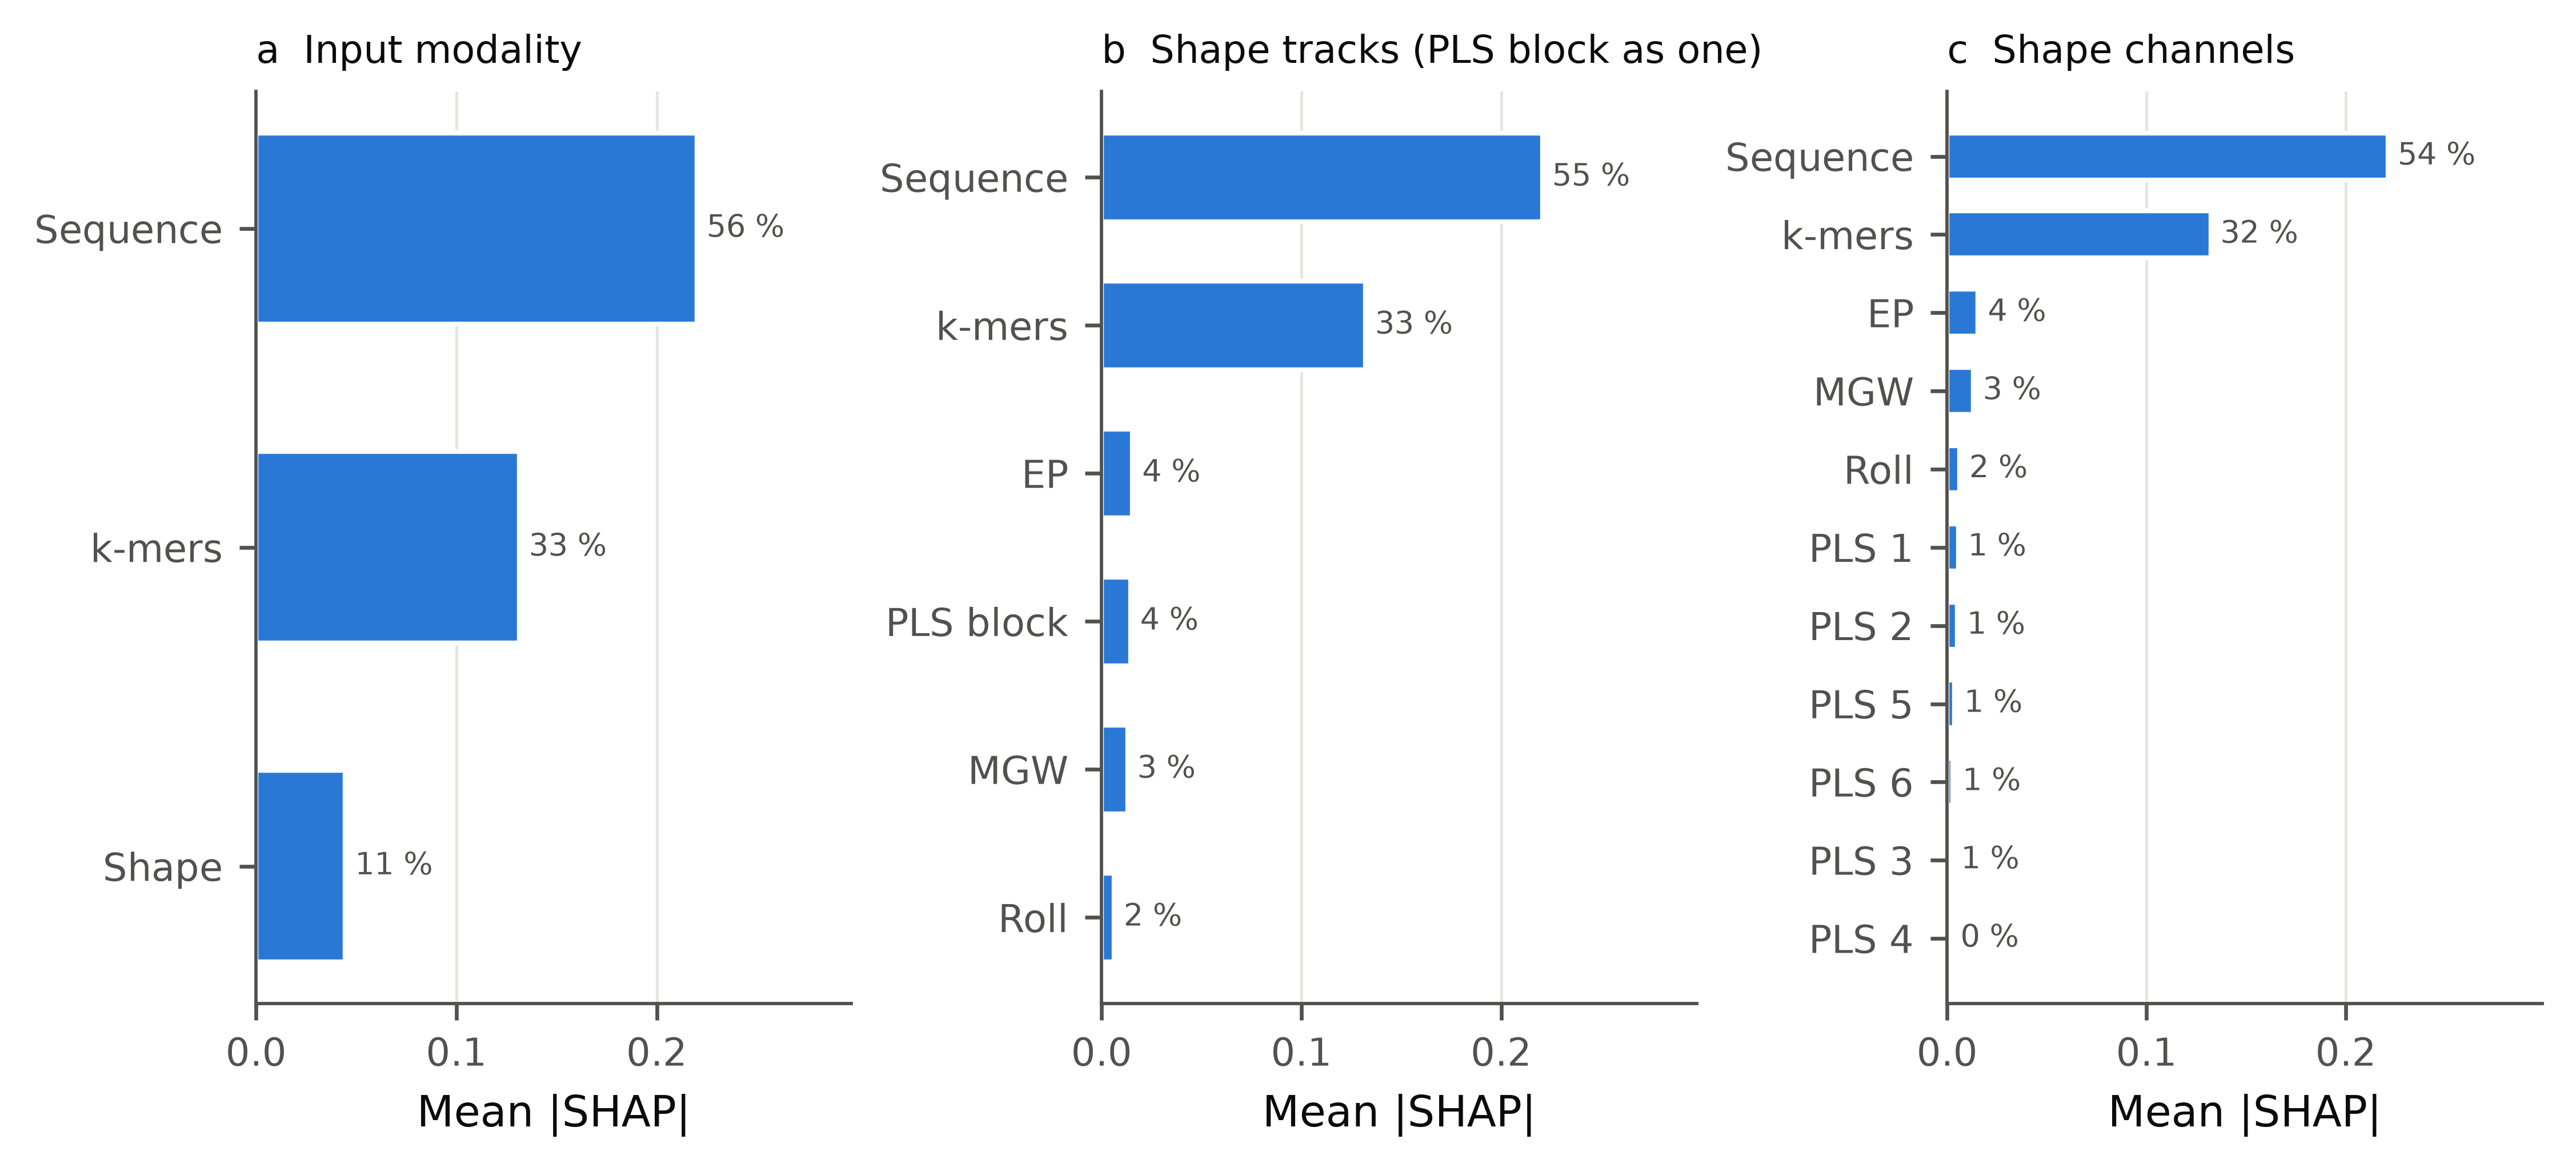

**shap_modality** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_modality.png`  
Exact group Shapley values of the reported nucleosome probability, input modality level (1000 held-out test sequences, 5 outer fold(s); background: class-balanced training rows of each fold). Left: mean absolute contribution (bars: all sequences; dots: per fold). Right: mean signed contribution by observed class (positive pushes towards nucleosome).

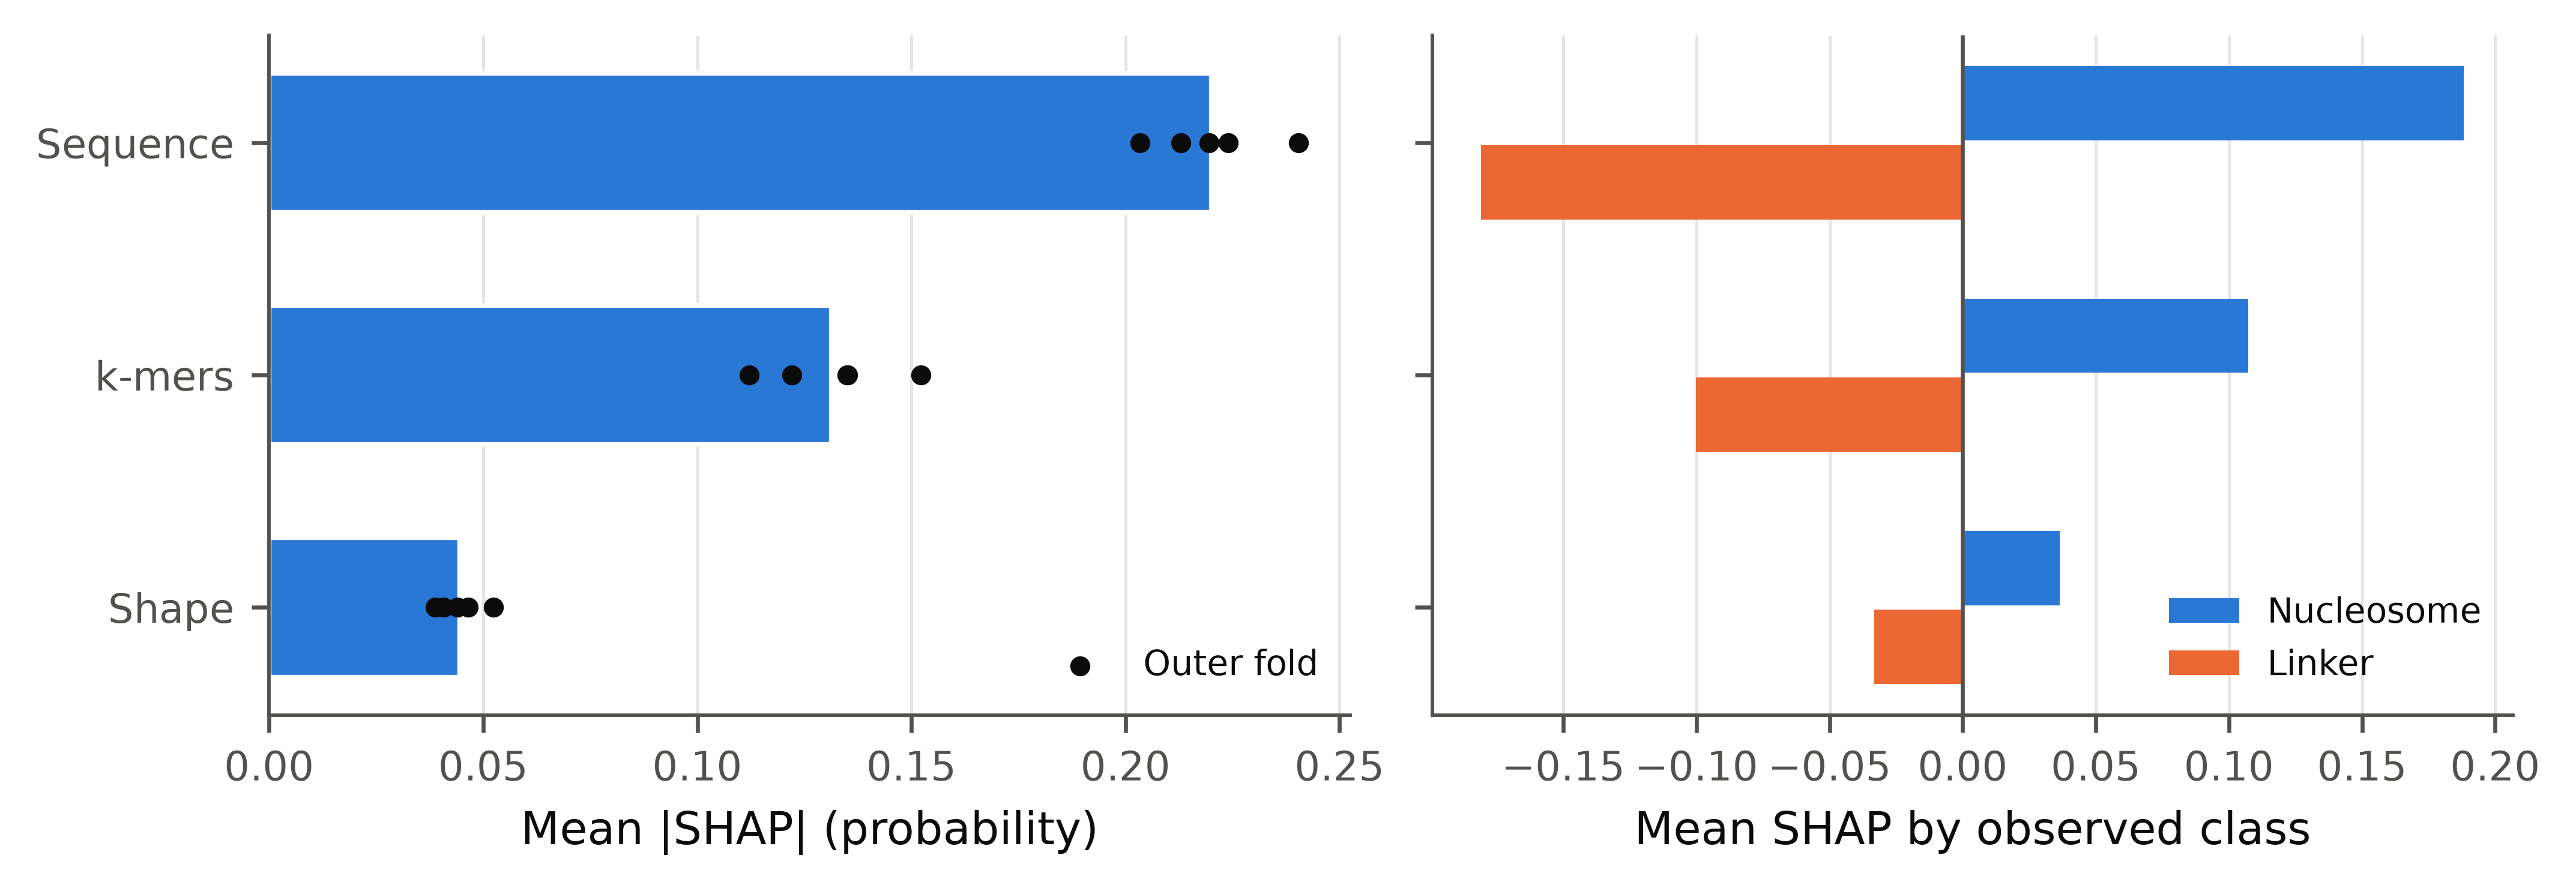

**shap_tracks** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_tracks.png`  
Exact group Shapley values of the reported nucleosome probability, shape tracks (pls block as one) level (1000 held-out test sequences, 5 outer fold(s); background: class-balanced training rows of each fold). Left: mean absolute contribution (bars: all sequences; dots: per fold). Right: mean signed contribution by observed class (positive pushes towards nucleosome).

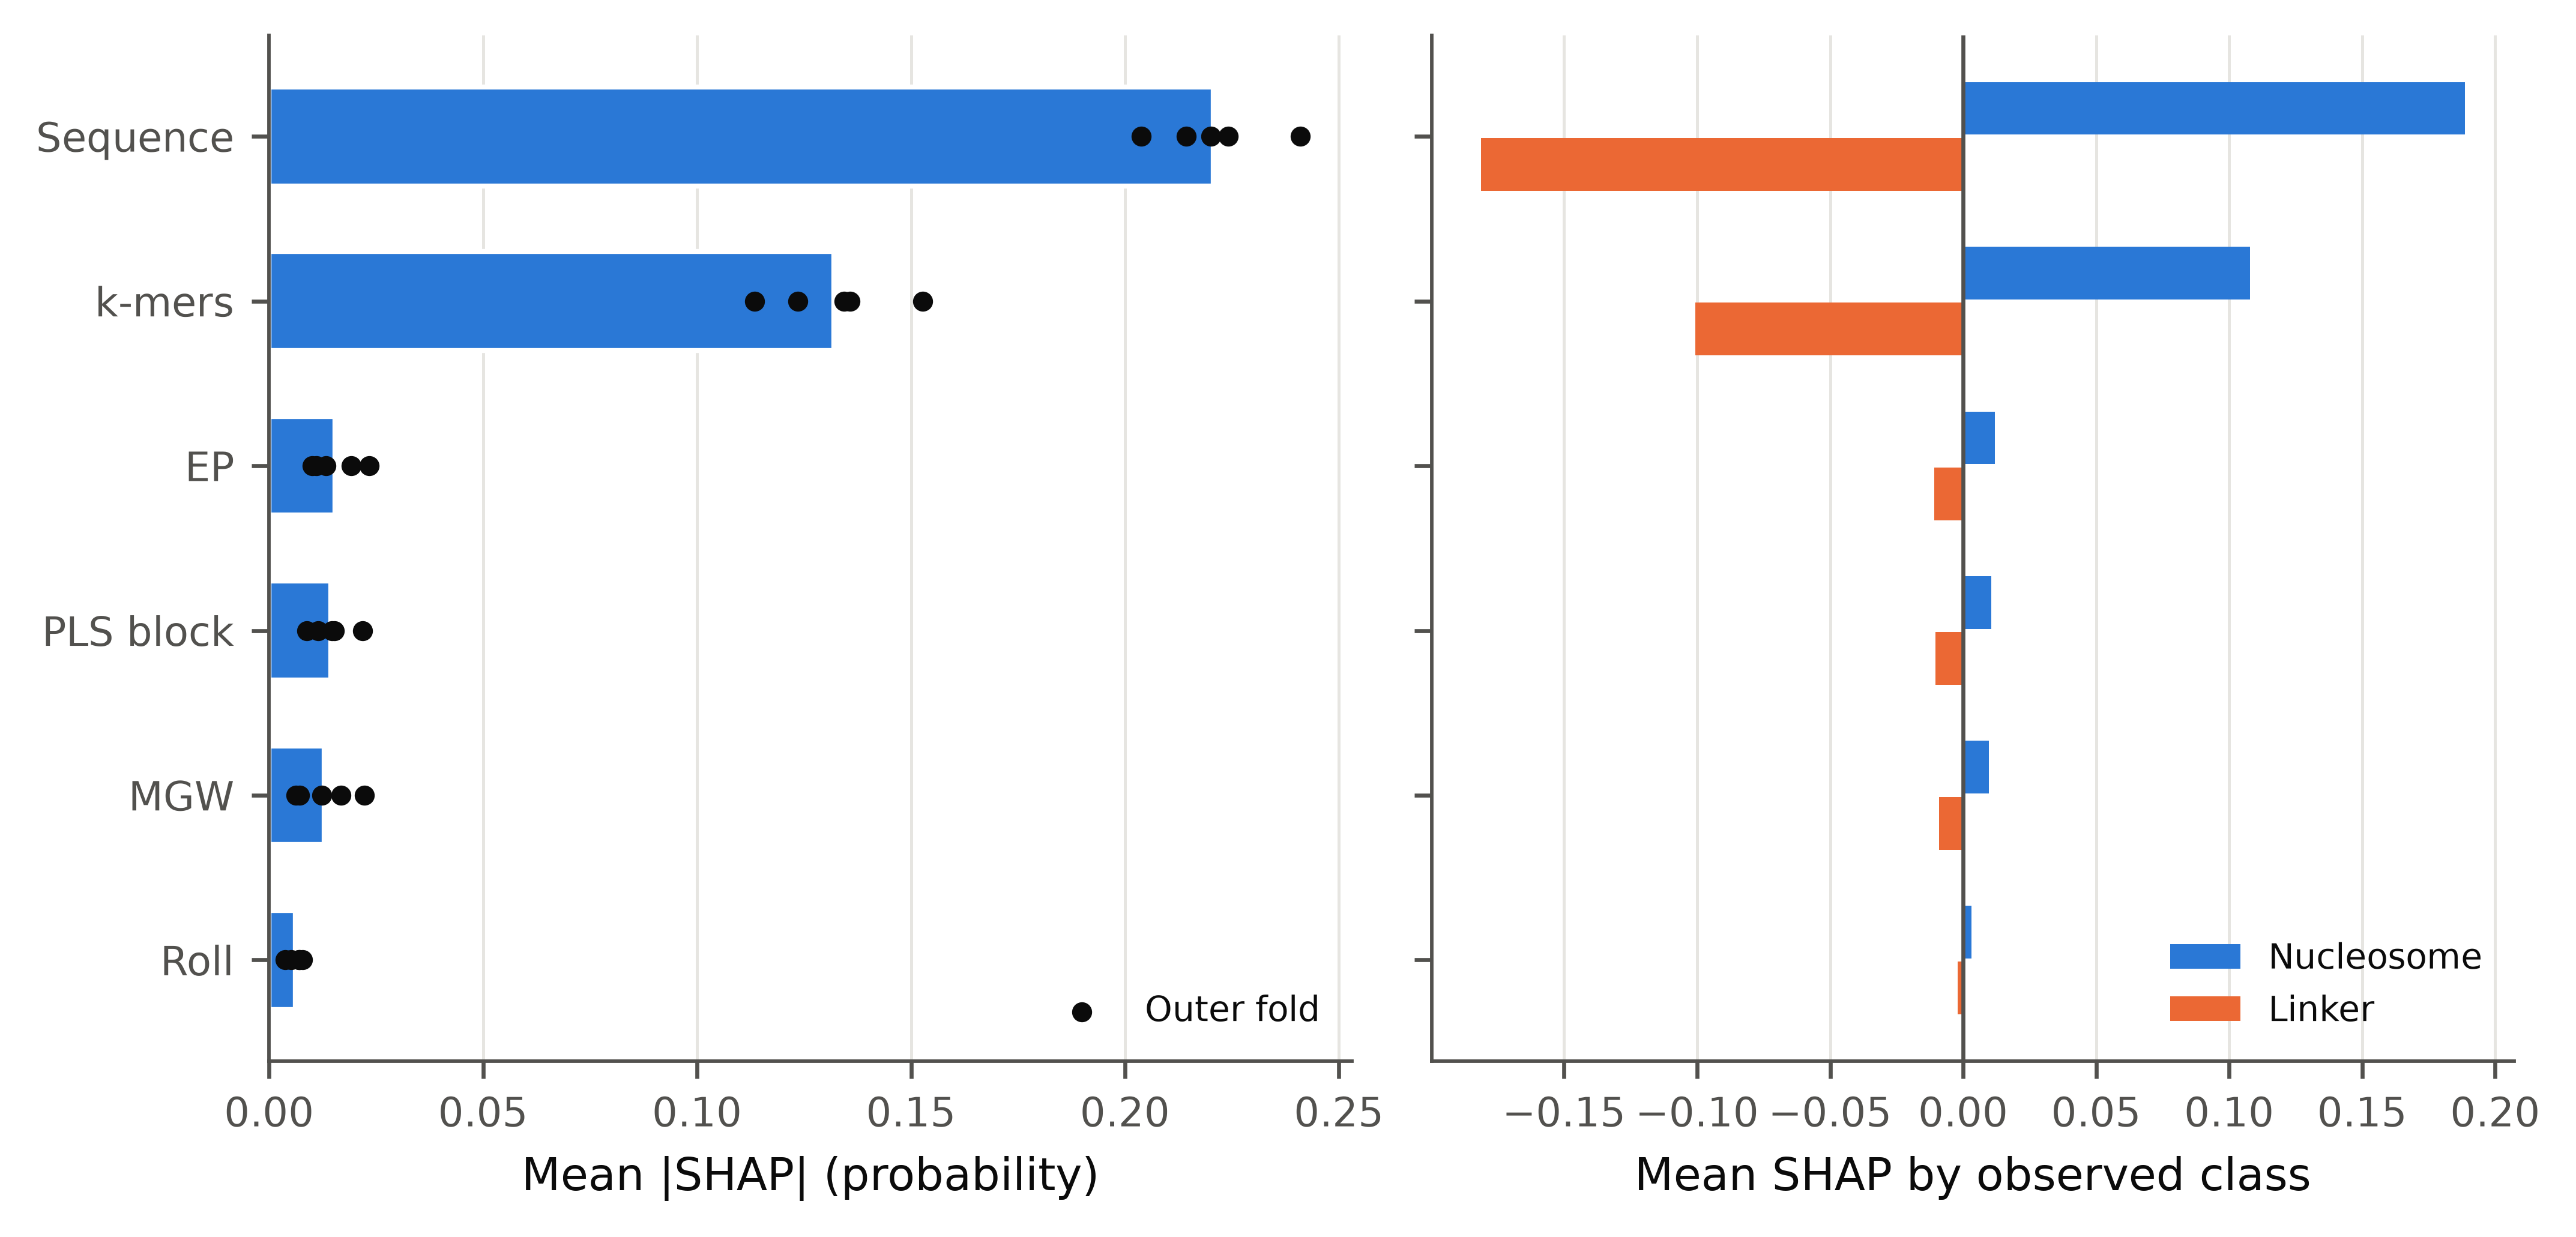

**shap_channels** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_channels.png`  
Exact group Shapley values of the reported nucleosome probability, shape channels level (1000 held-out test sequences, 5 outer fold(s); background: class-balanced training rows of each fold). Left: mean absolute contribution (bars: all sequences; dots: per fold). Right: mean signed contribution by observed class (positive pushes towards nucleosome).

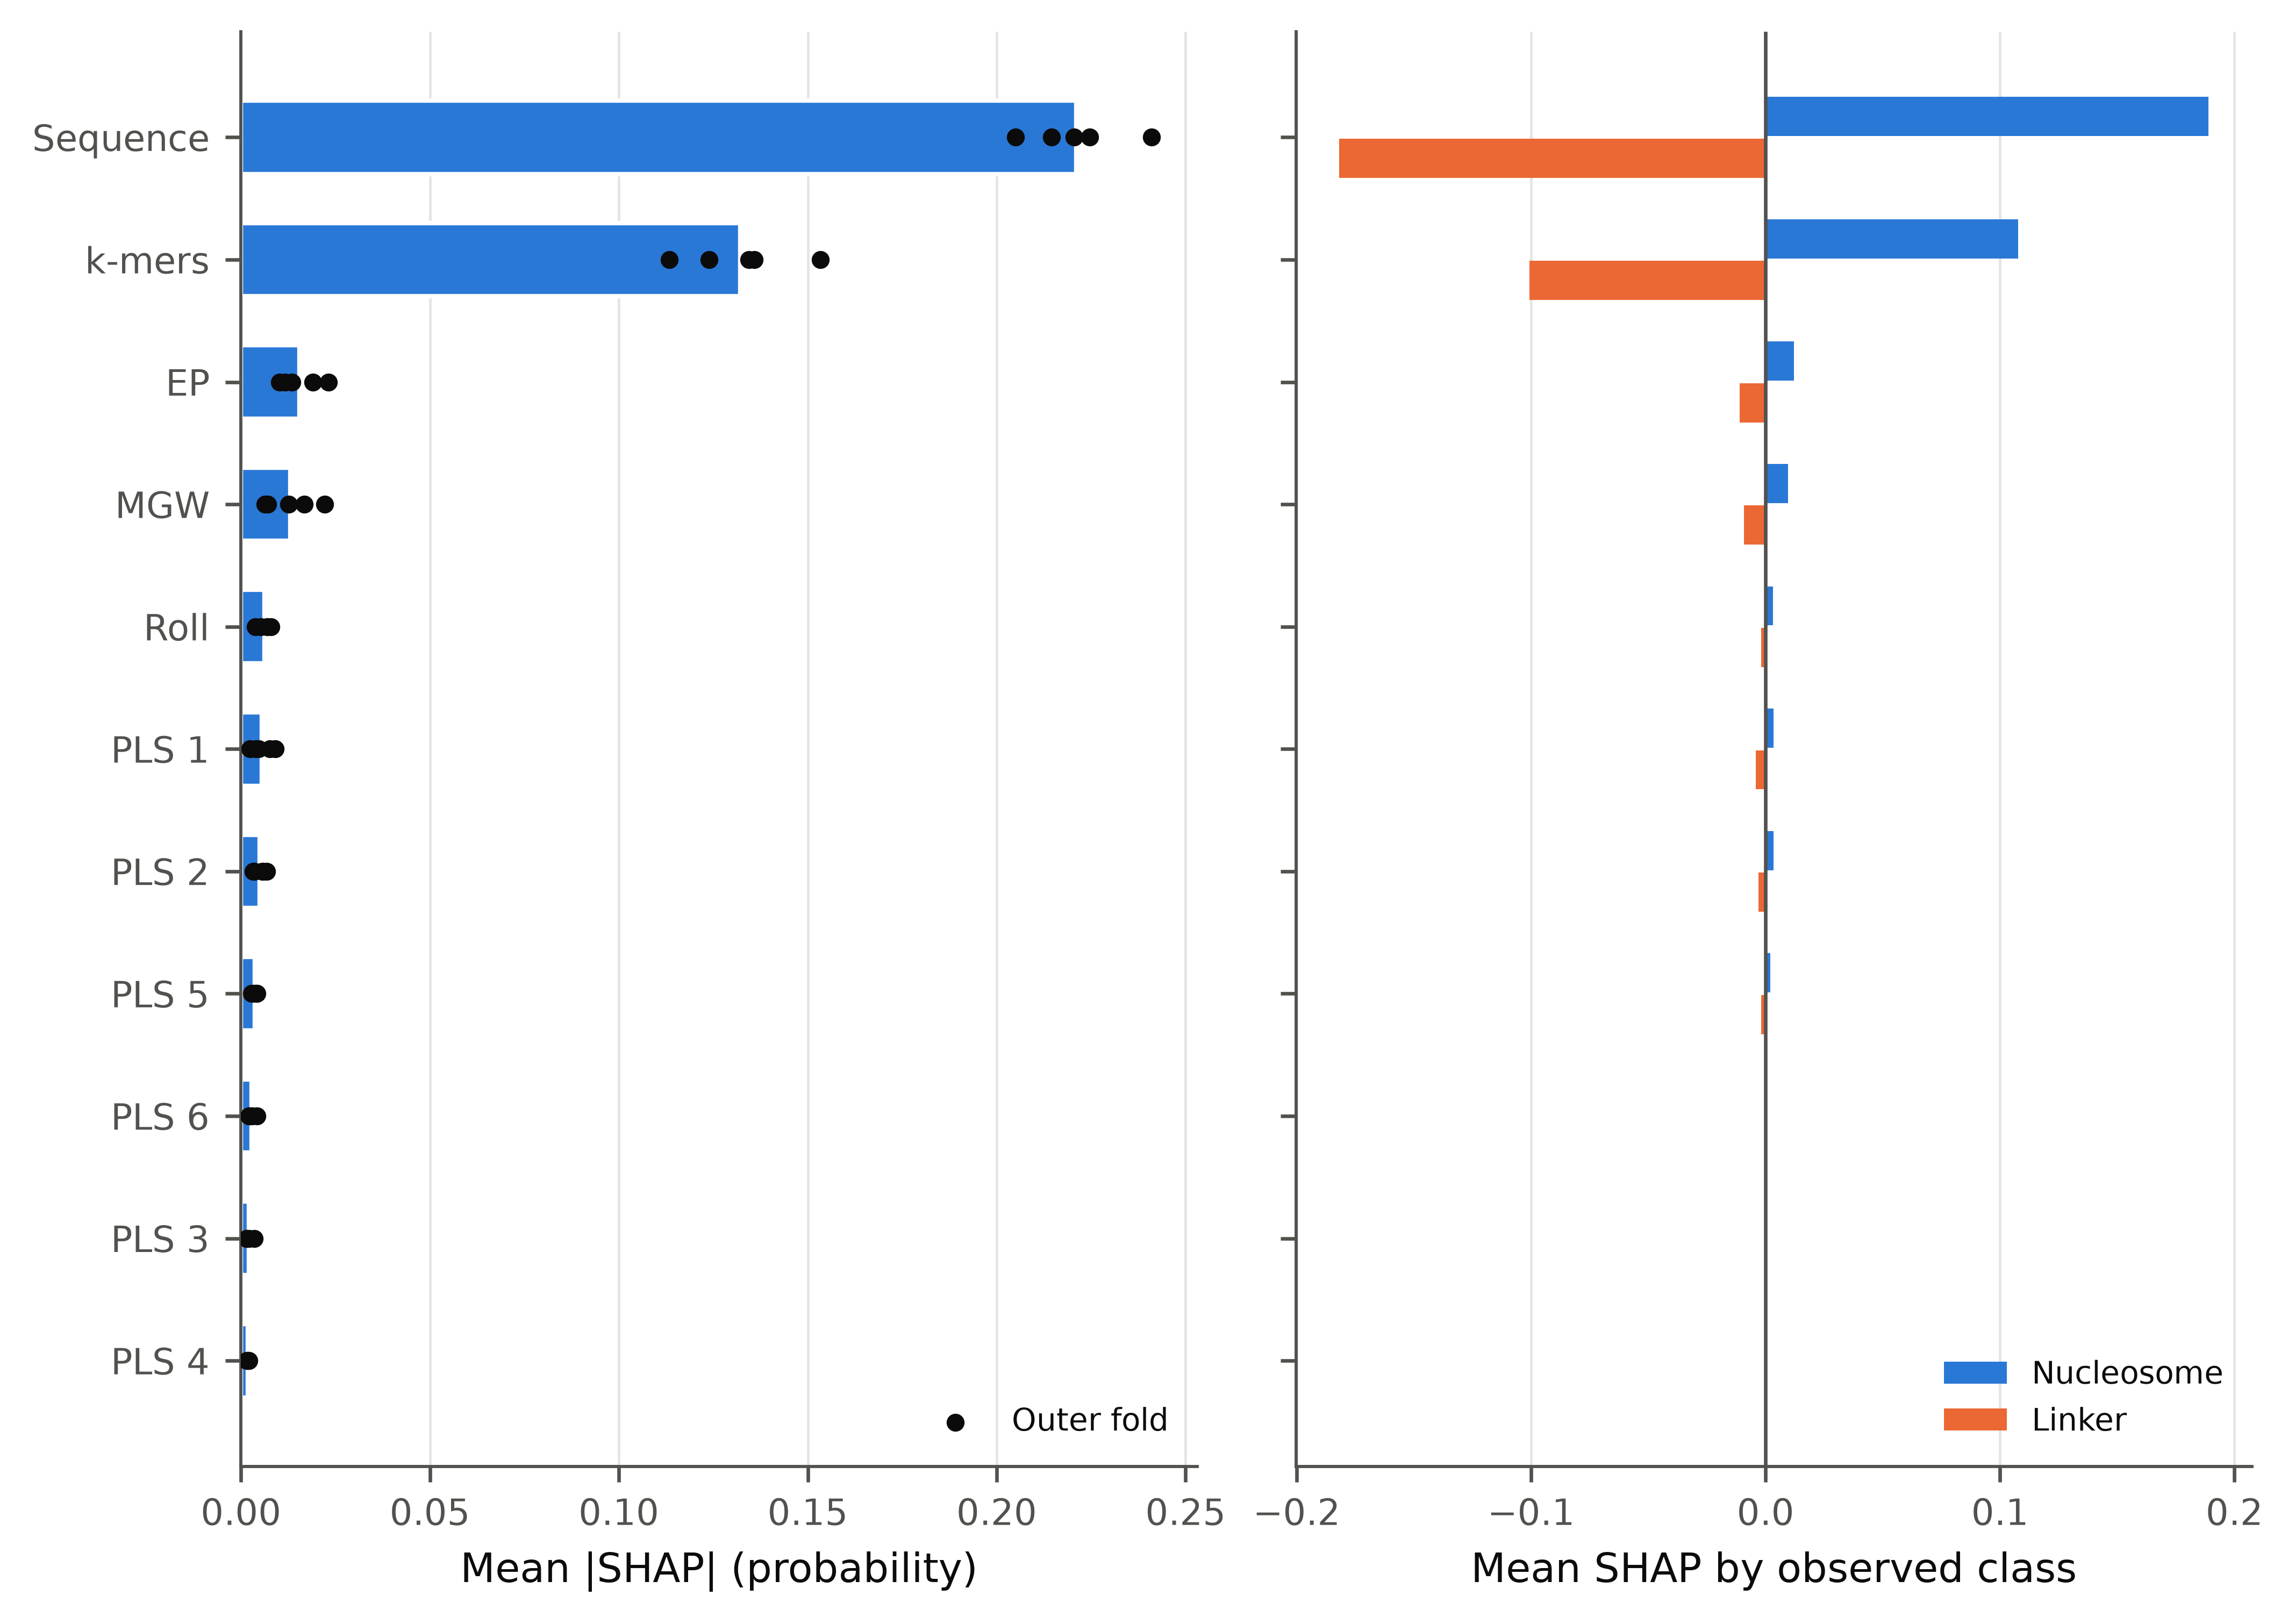

**shap_beeswarm_tracks** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_beeswarm_tracks.png`  
SHAP summary plot, shape tracks (pls block as one) level: one dot per explained test sequence (1000, 5 fold(s)), coloured by the rank of a scalar summary of that player's input (sequence and k-mers: GC fraction; a shape channel: its mean over the 143 positions; the PLS block: the mean of PLS 1). The summary is a reading aid; the player itself is the whole input group.

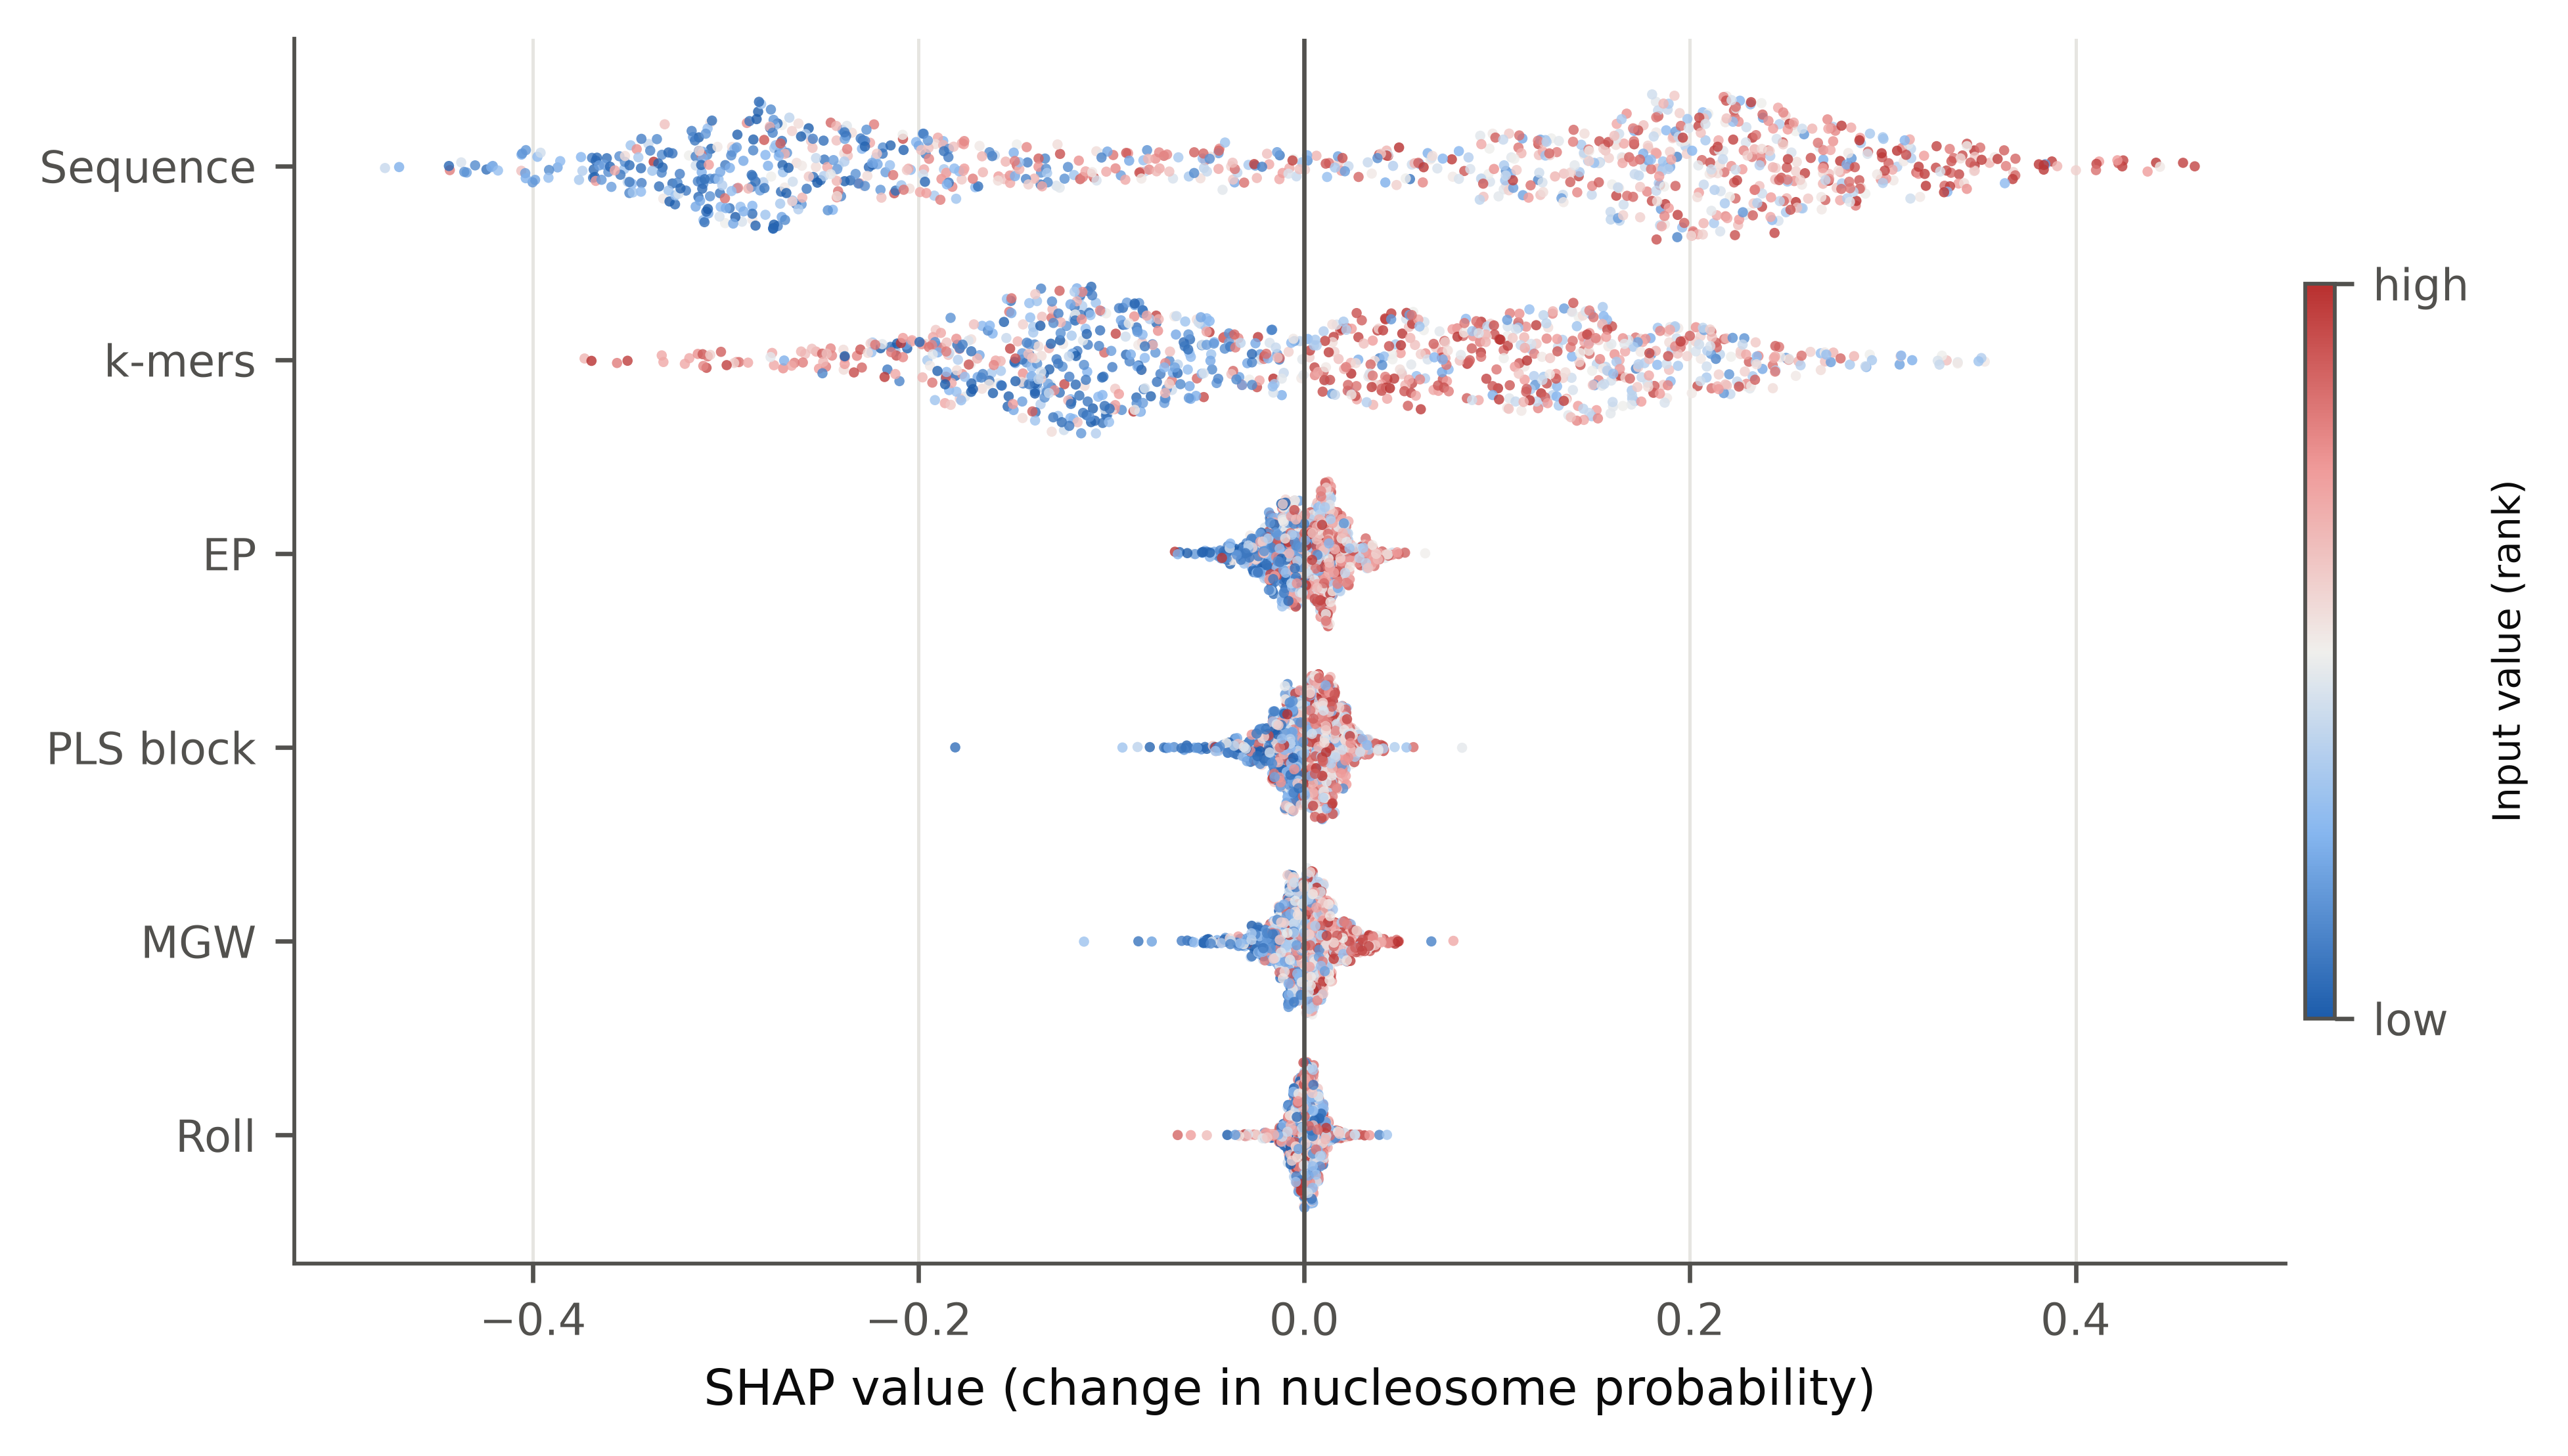

**shap_beeswarm_channels** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_beeswarm_channels.png`  
SHAP summary plot, shape channels level: one dot per explained test sequence (1000, 5 fold(s)), coloured by the rank of a scalar summary of that player's input (sequence and k-mers: GC fraction; a shape channel: its mean over the 143 positions; the PLS block: the mean of PLS 1). The summary is a reading aid; the player itself is the whole input group.

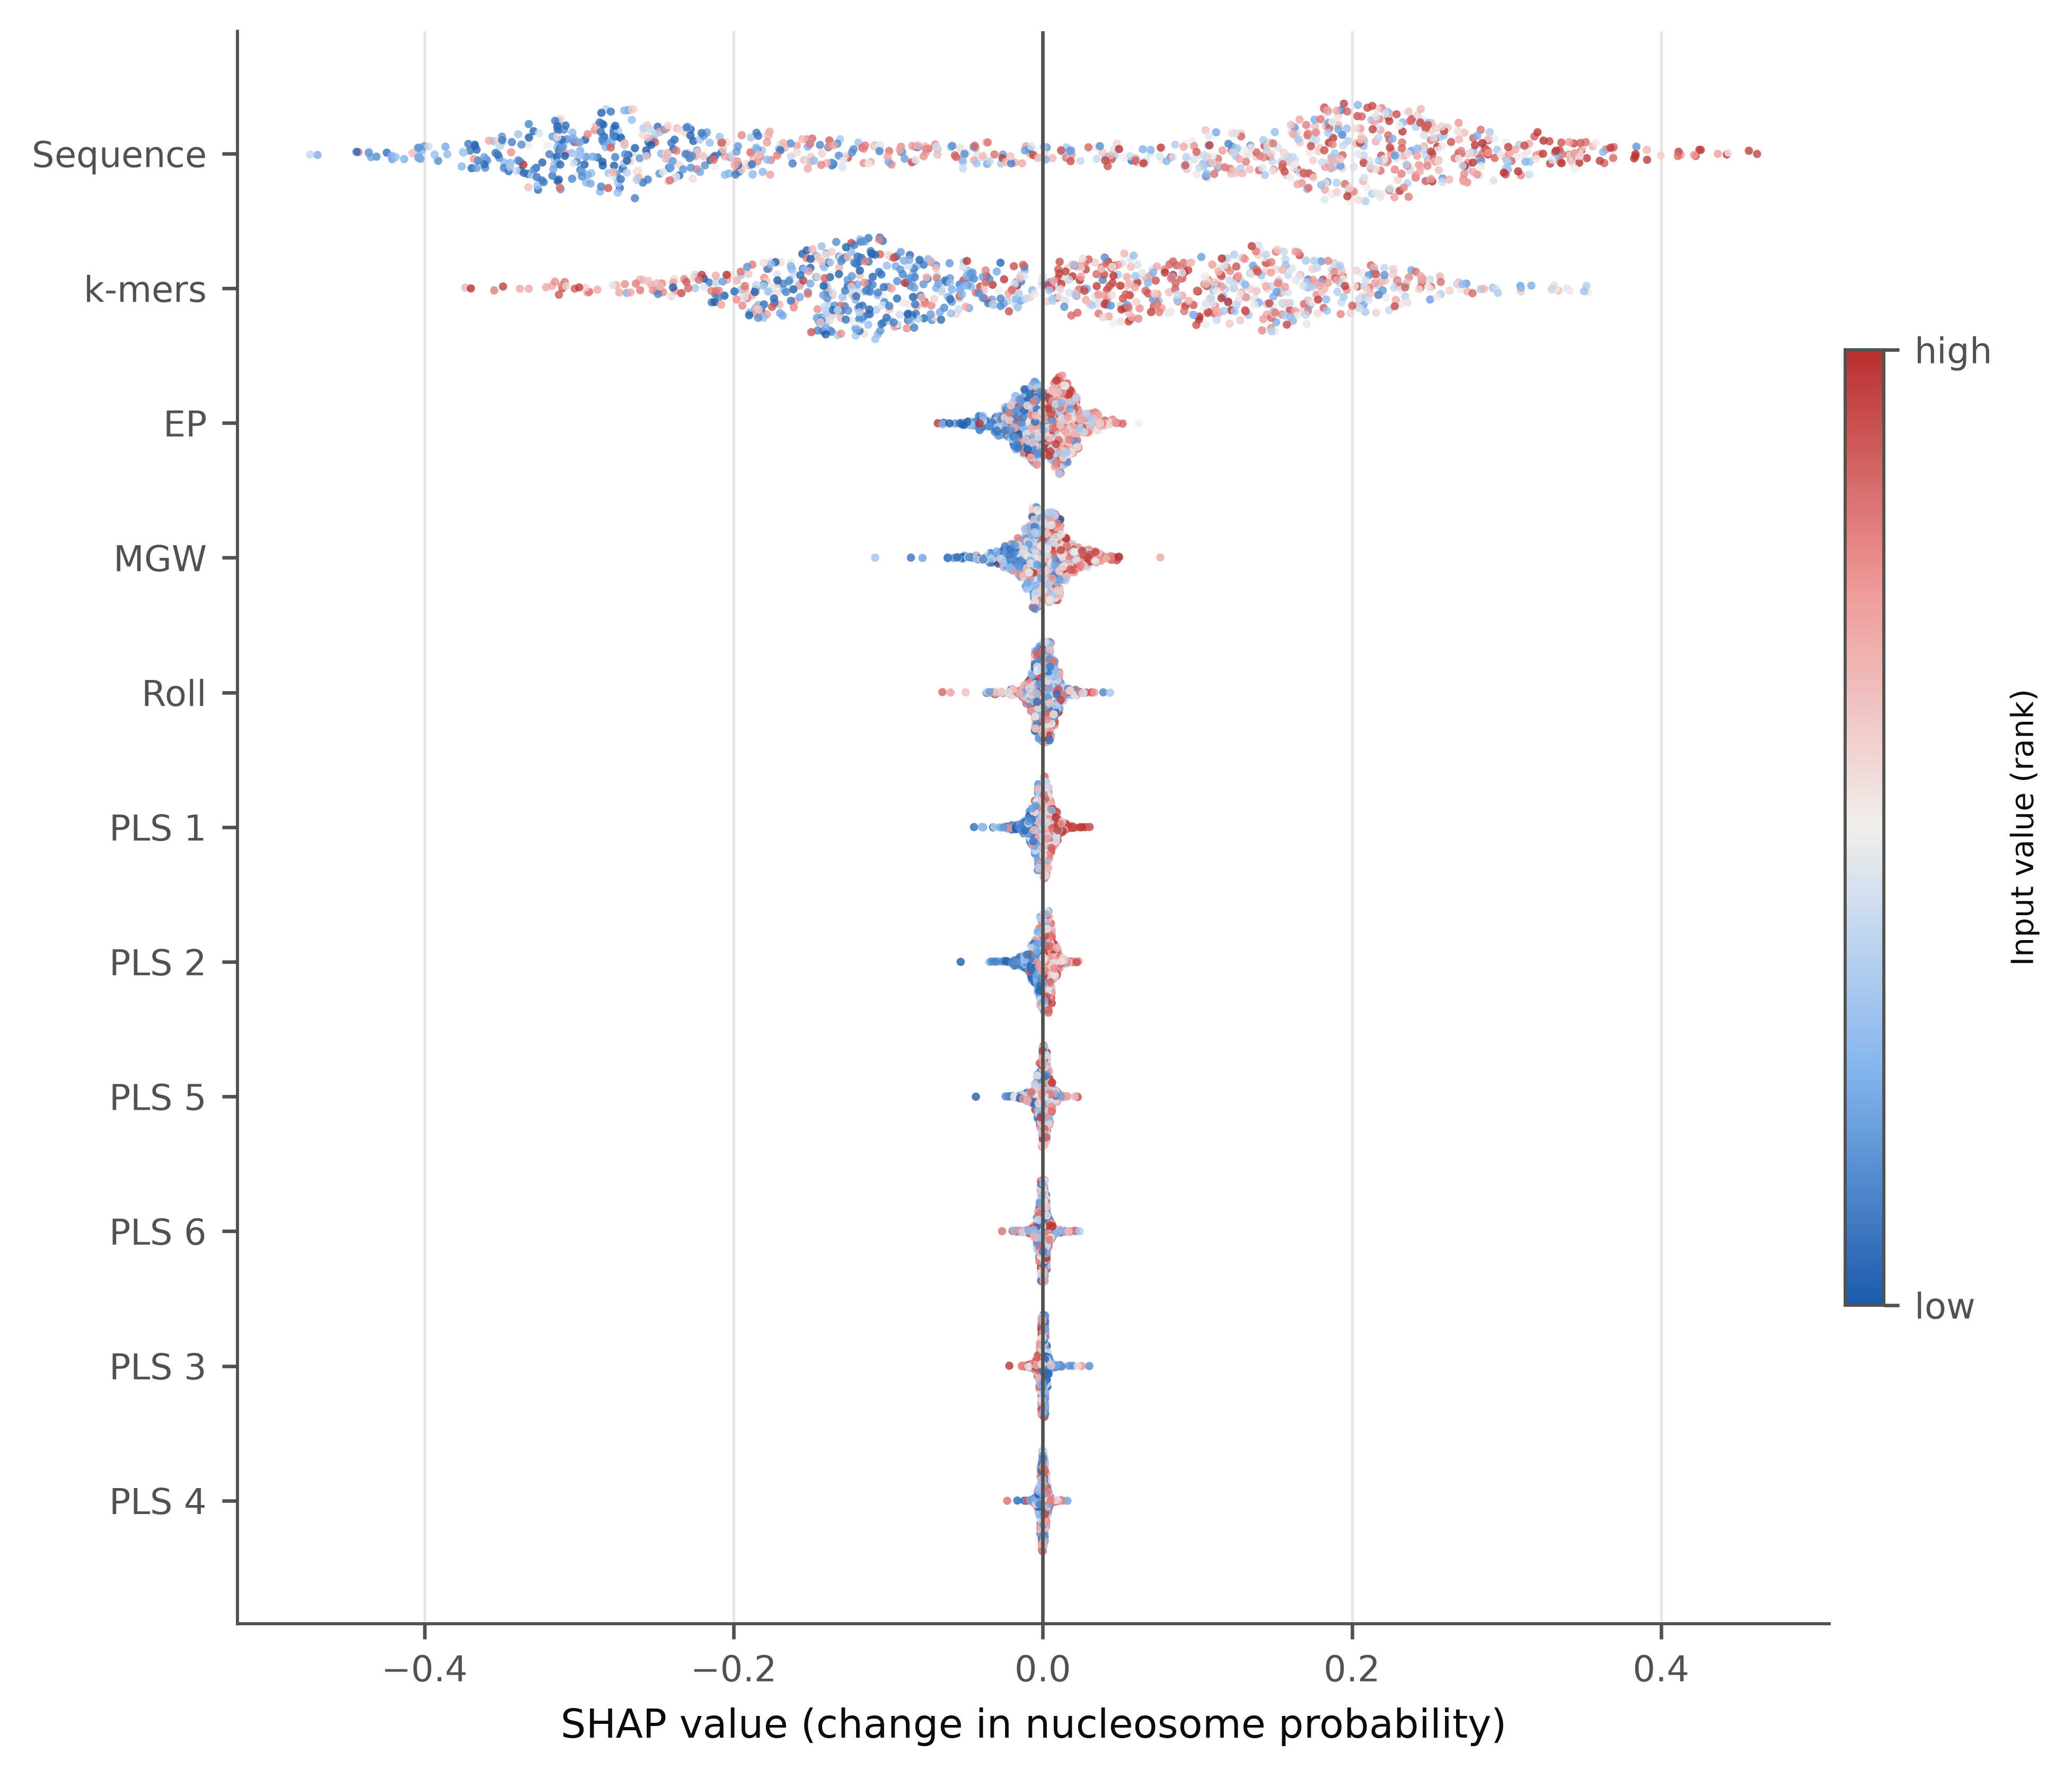

**shap_dependence_tracks** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_dependence_tracks.png`  
SHAP dependence, tracks level: each player's Shapley value against a scalar summary of its input (as in the summary plot), coloured by observed class; ρ: Spearman correlation over all explained sequences.

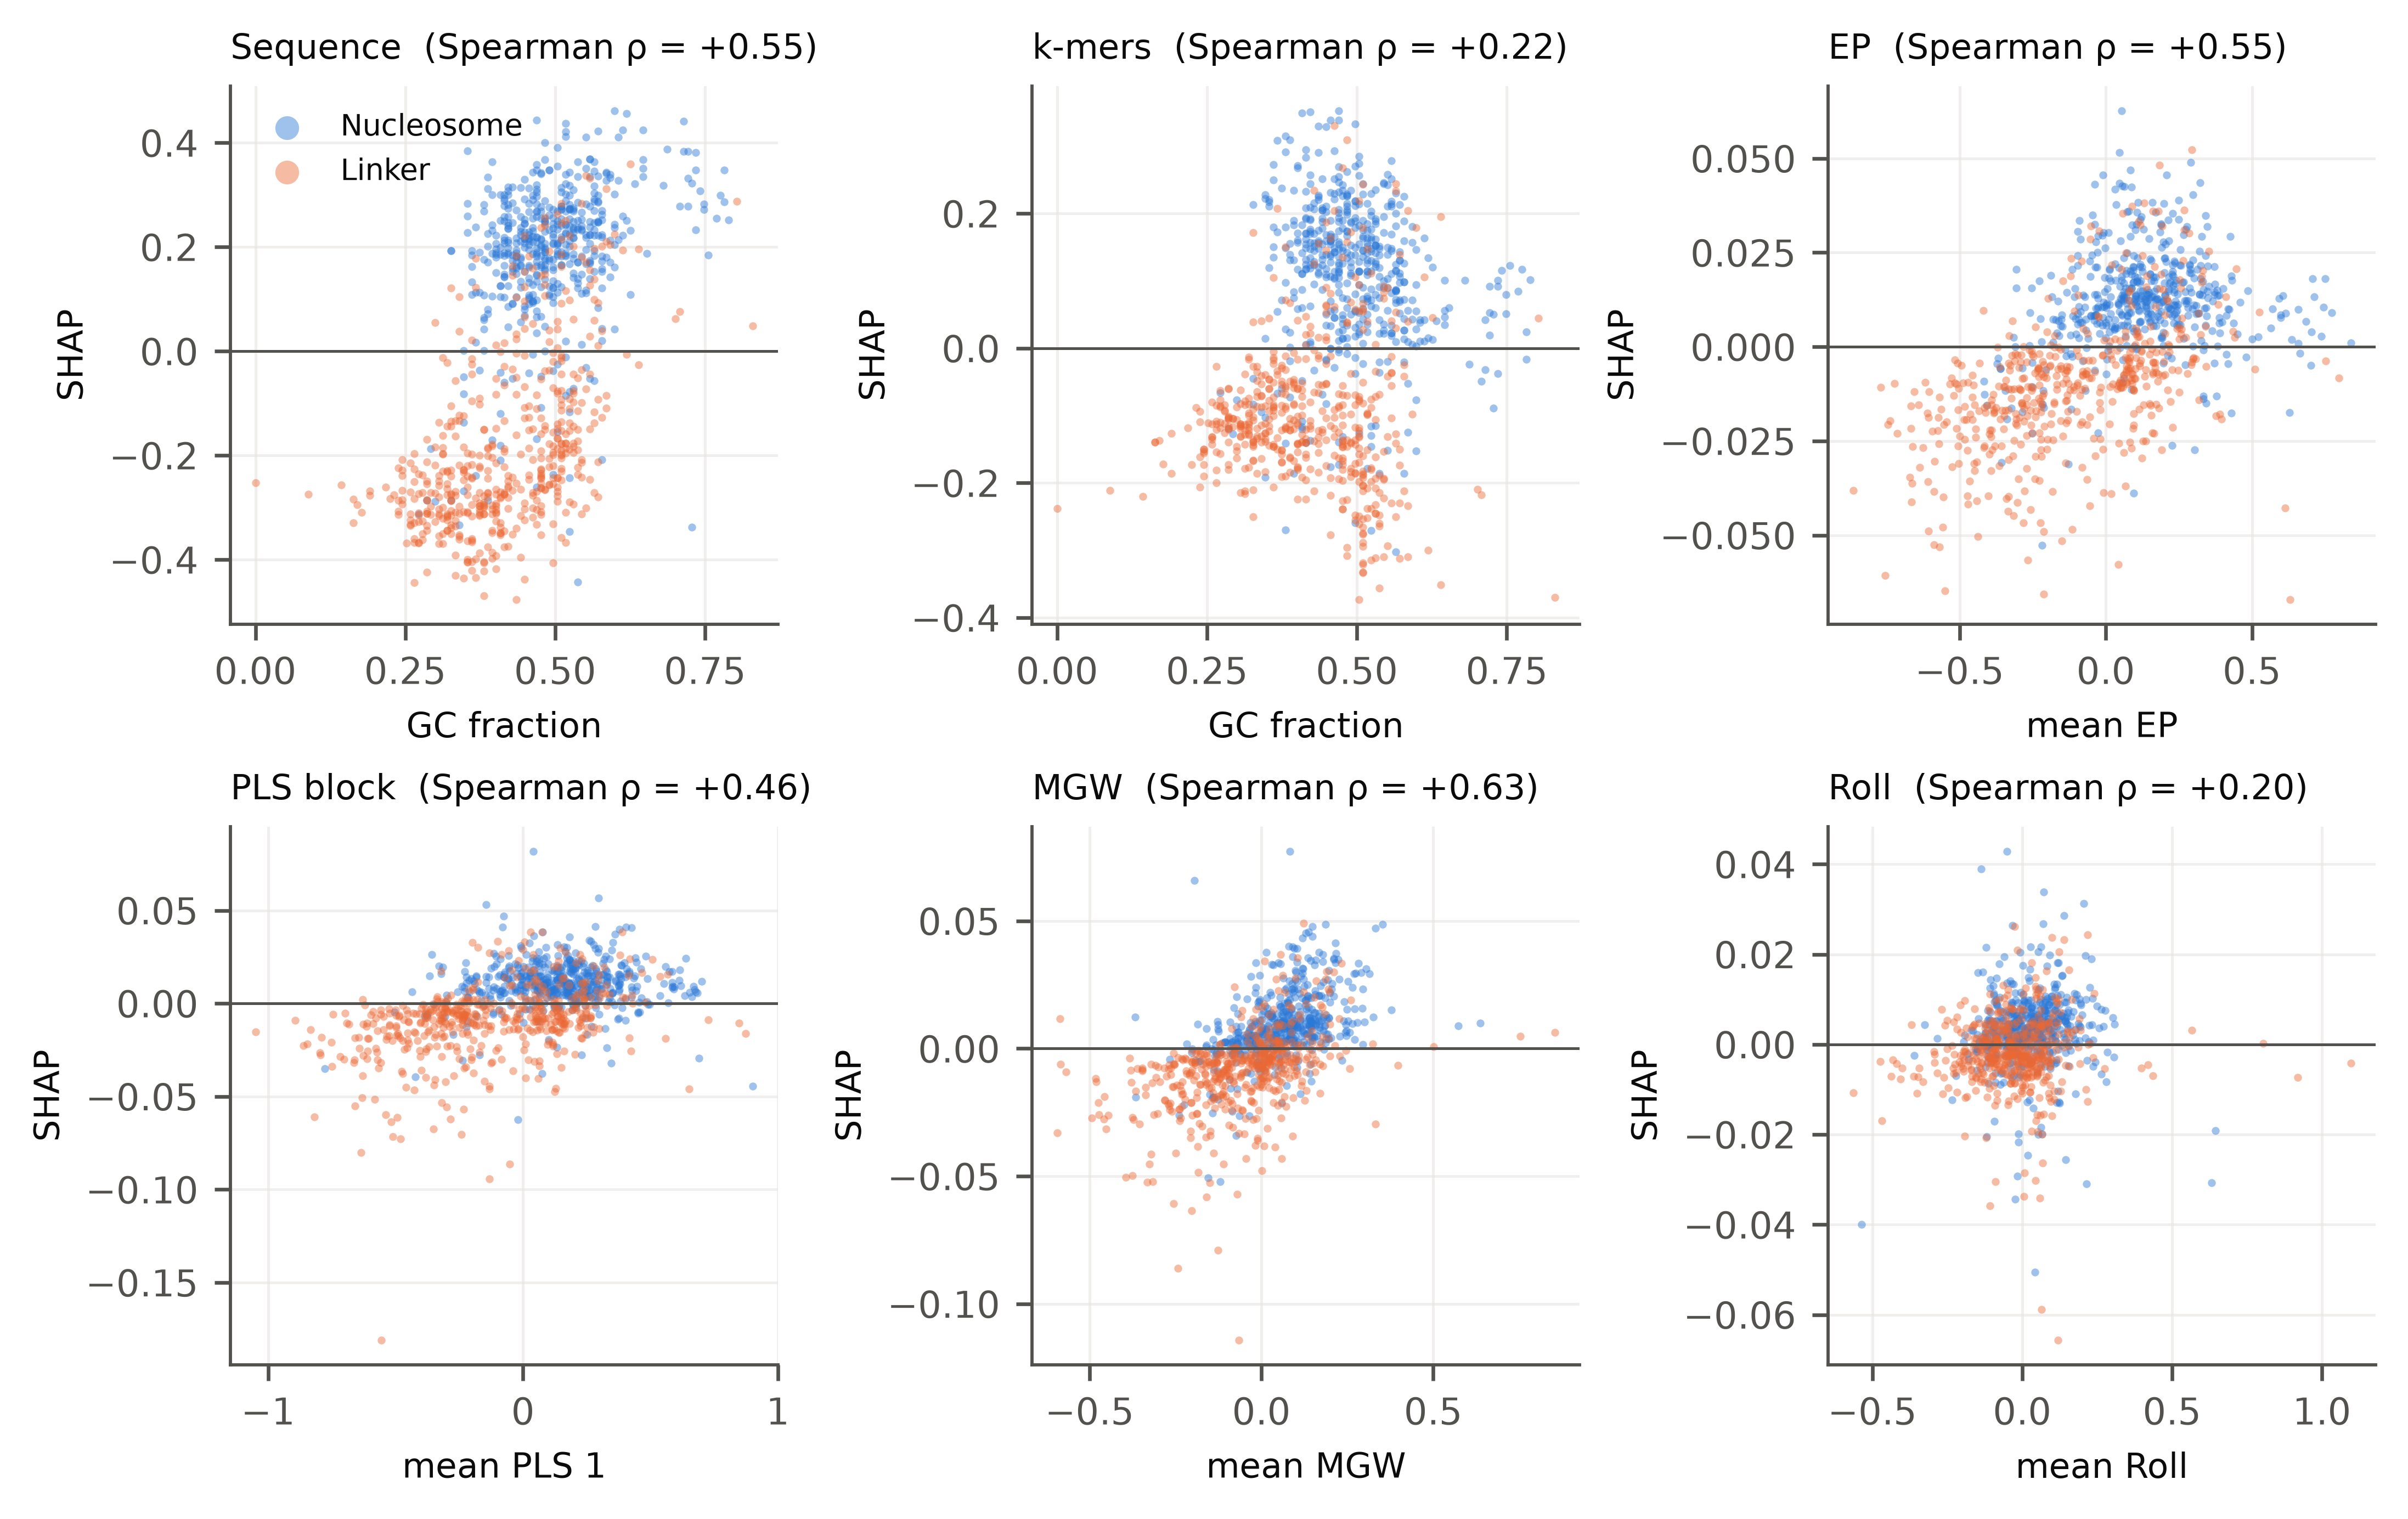

**shap_distribution_tracks** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_distribution_tracks.png`  
Group Shapley value of every explained test sequence, tracks level, by observed class.

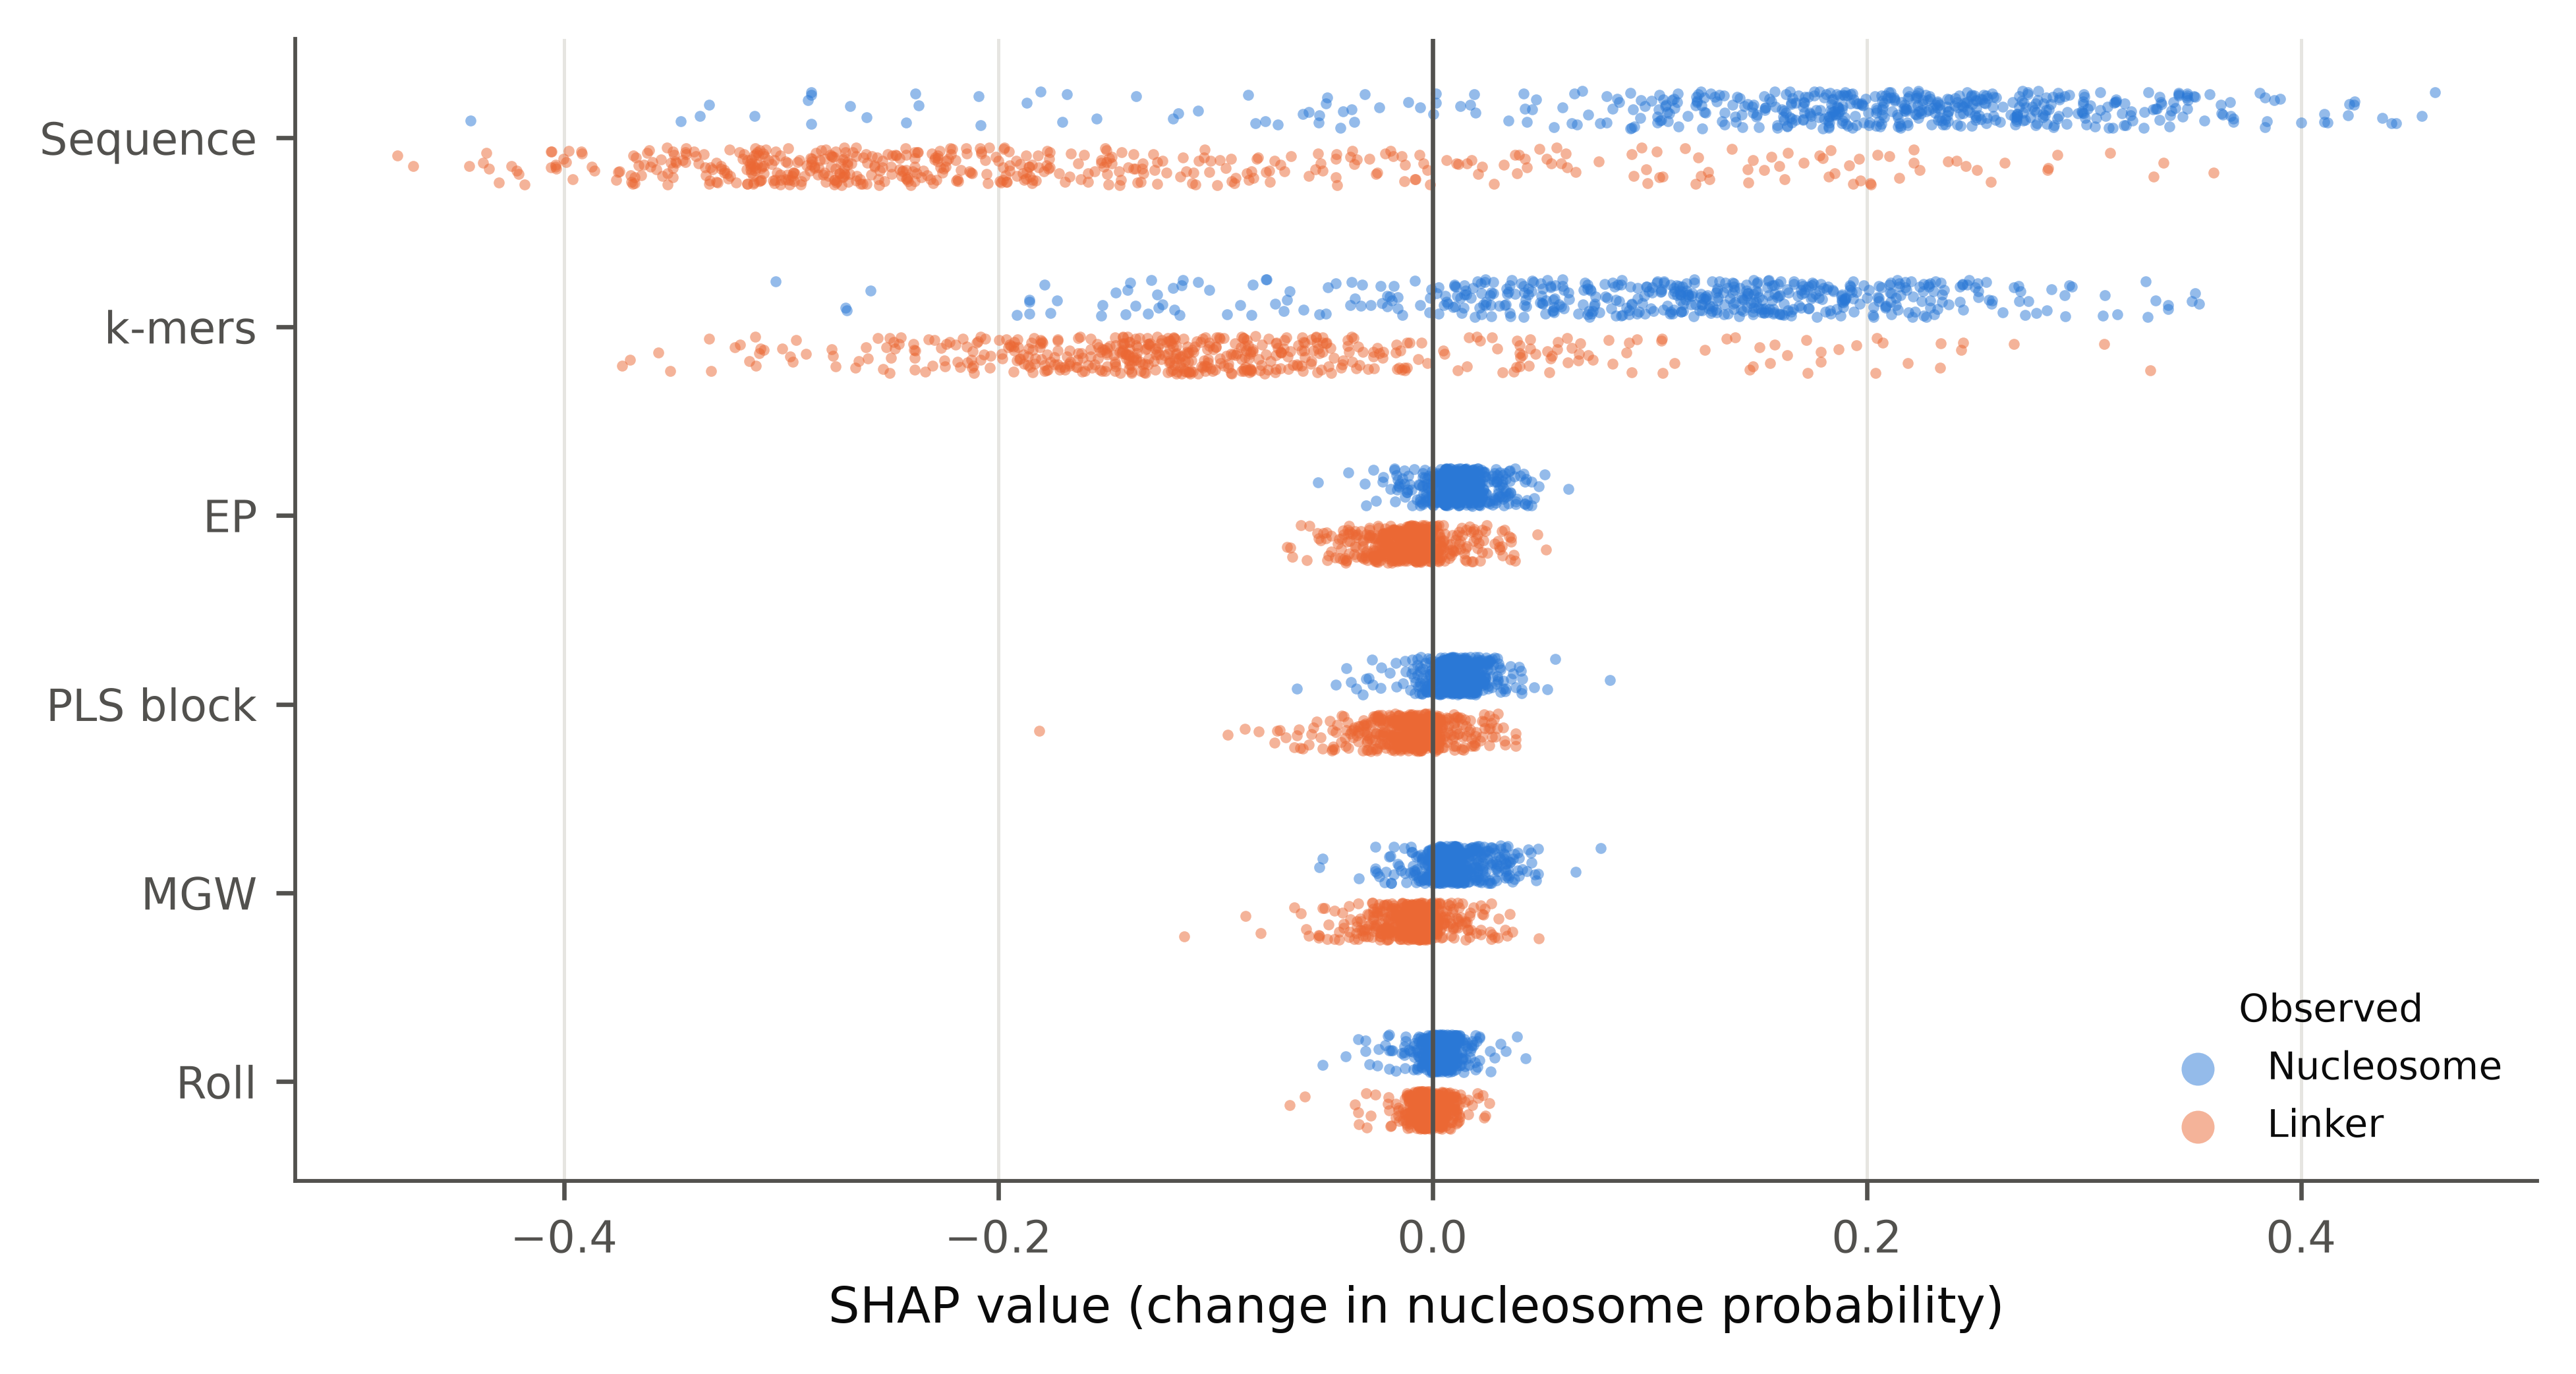

**shap_by_outcome_tracks** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_by_outcome_tracks.png`  
Mean group Shapley value per player by prediction outcome (threshold 0.5): true positives (nucleosome, predicted nucleosome), false negatives, true negatives (linker, predicted linker) and false positives. Shows which inputs push the misclassified sequences the wrong way.

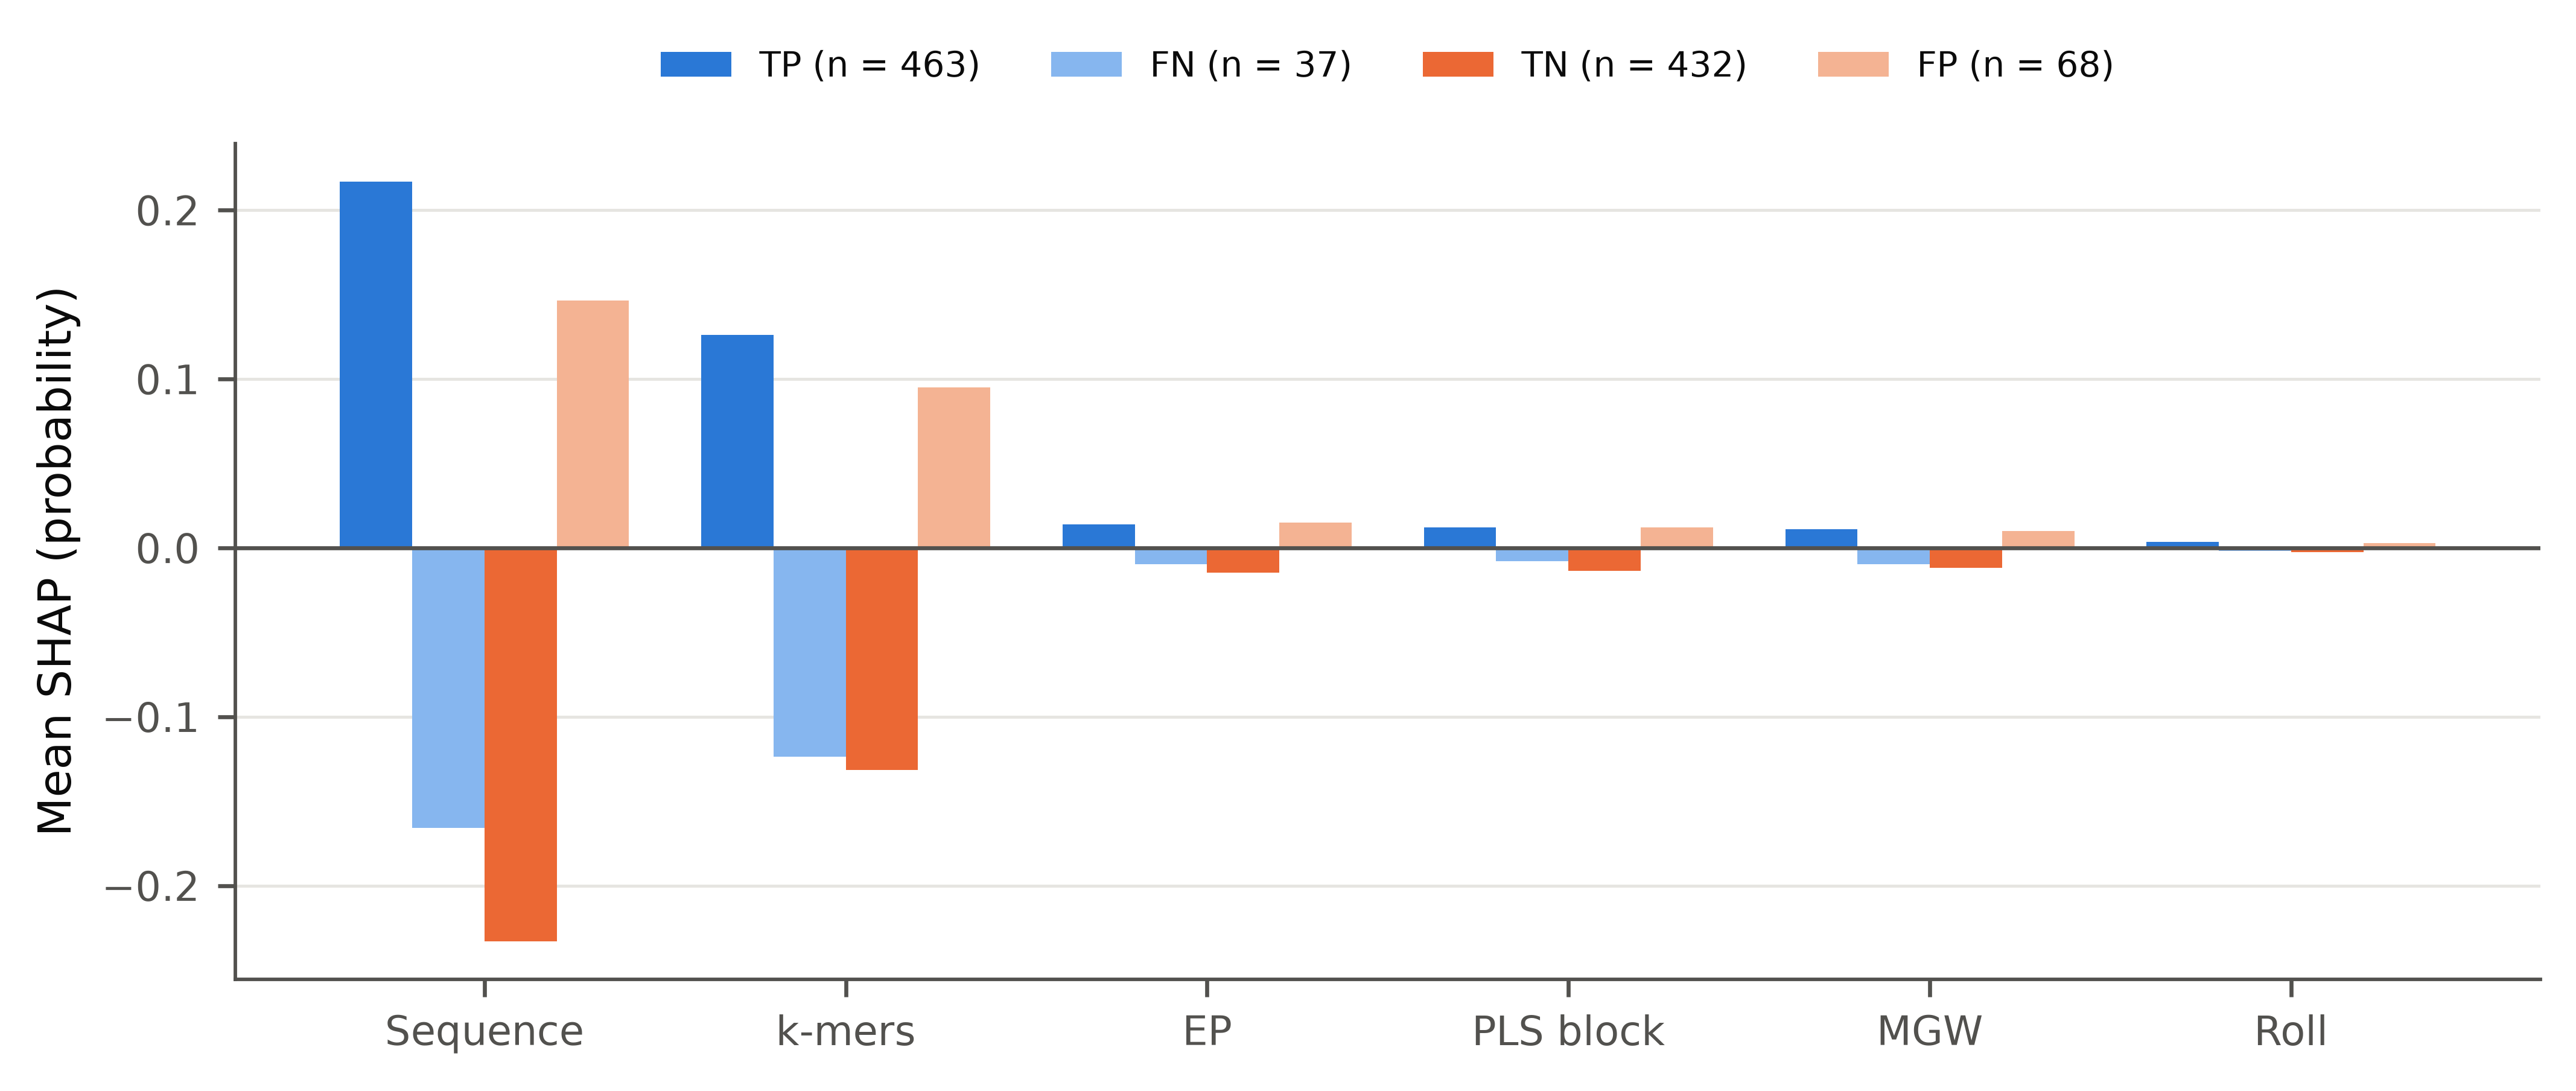

**shap_interactions_tracks** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/shap_interactions_tracks.png`  
Pairwise Shapley interaction index between players, tracks level (1000 test sequences): mean absolute value (in brackets: mean signed value). Large values mean that the two inputs act together rather than separately.

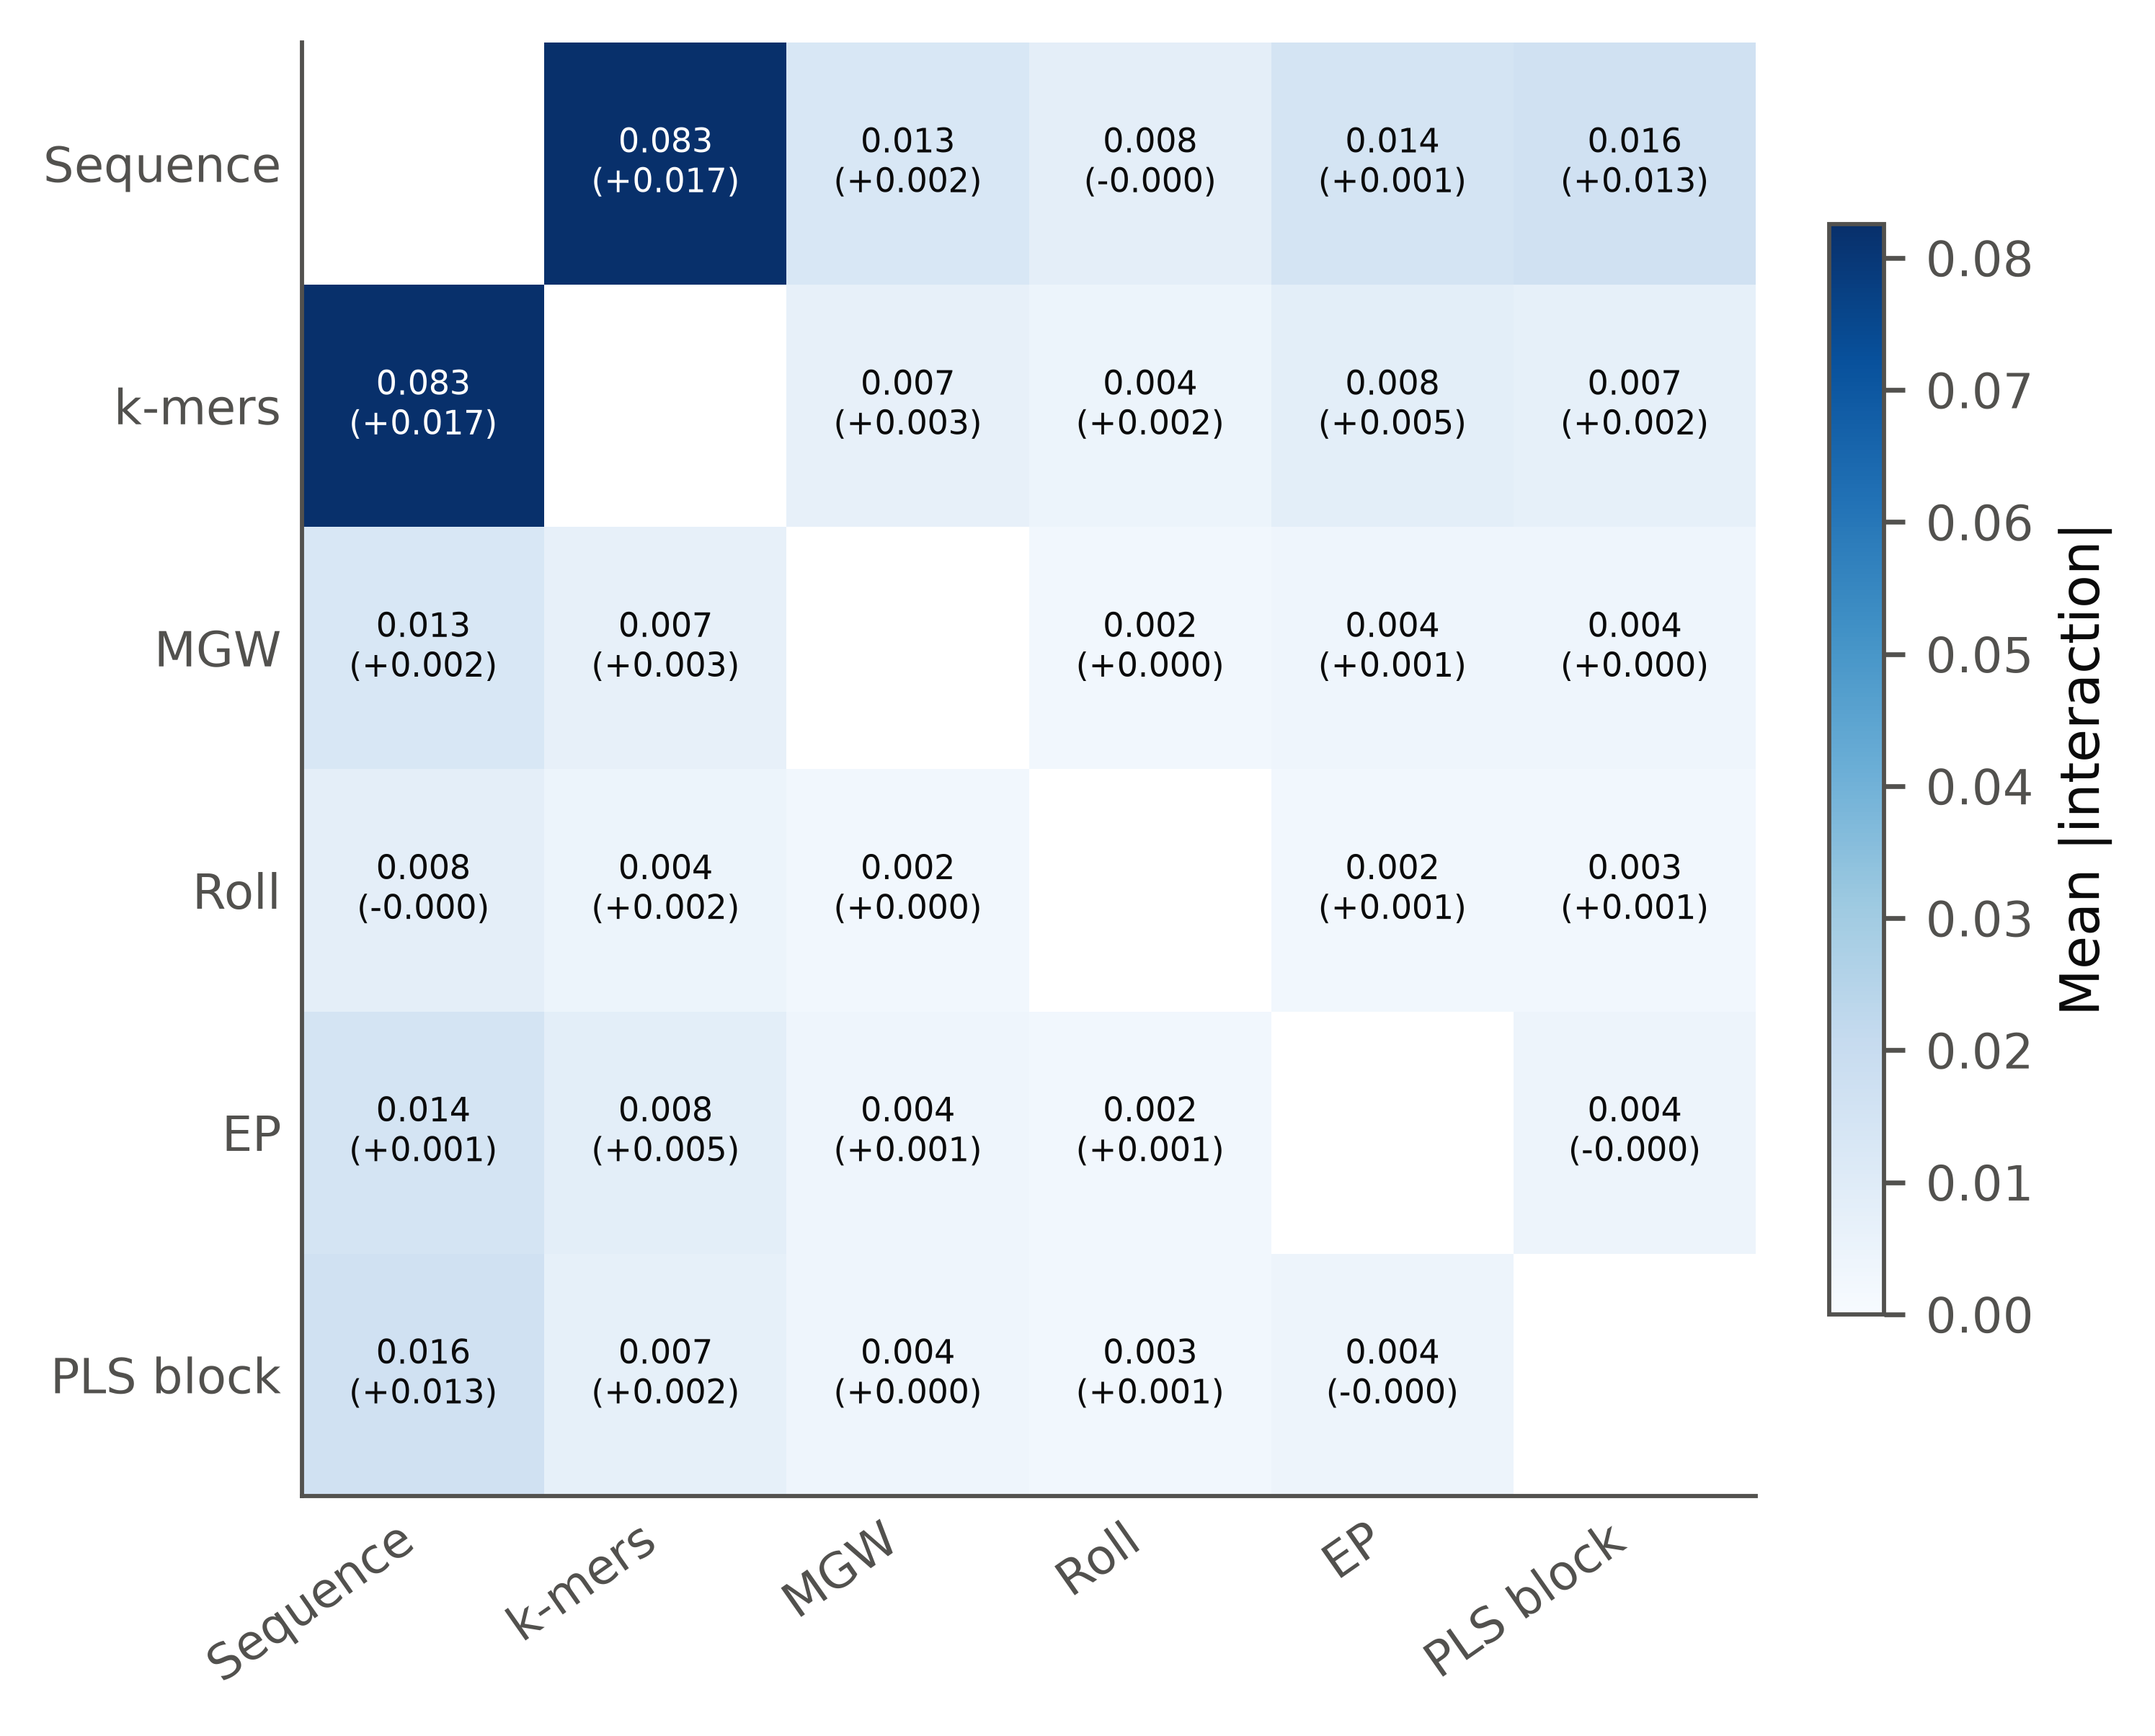

**attribution_agreement** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/attribution_agreement.png`  
Share of each input modality in the total absolute attribution by two methods on the same test sequences: exact group Shapley values (reported probability) and integrated gradients (summed over positions; logit). Agreement in ranking supports the attribution; magnitudes are not comparable between methods.

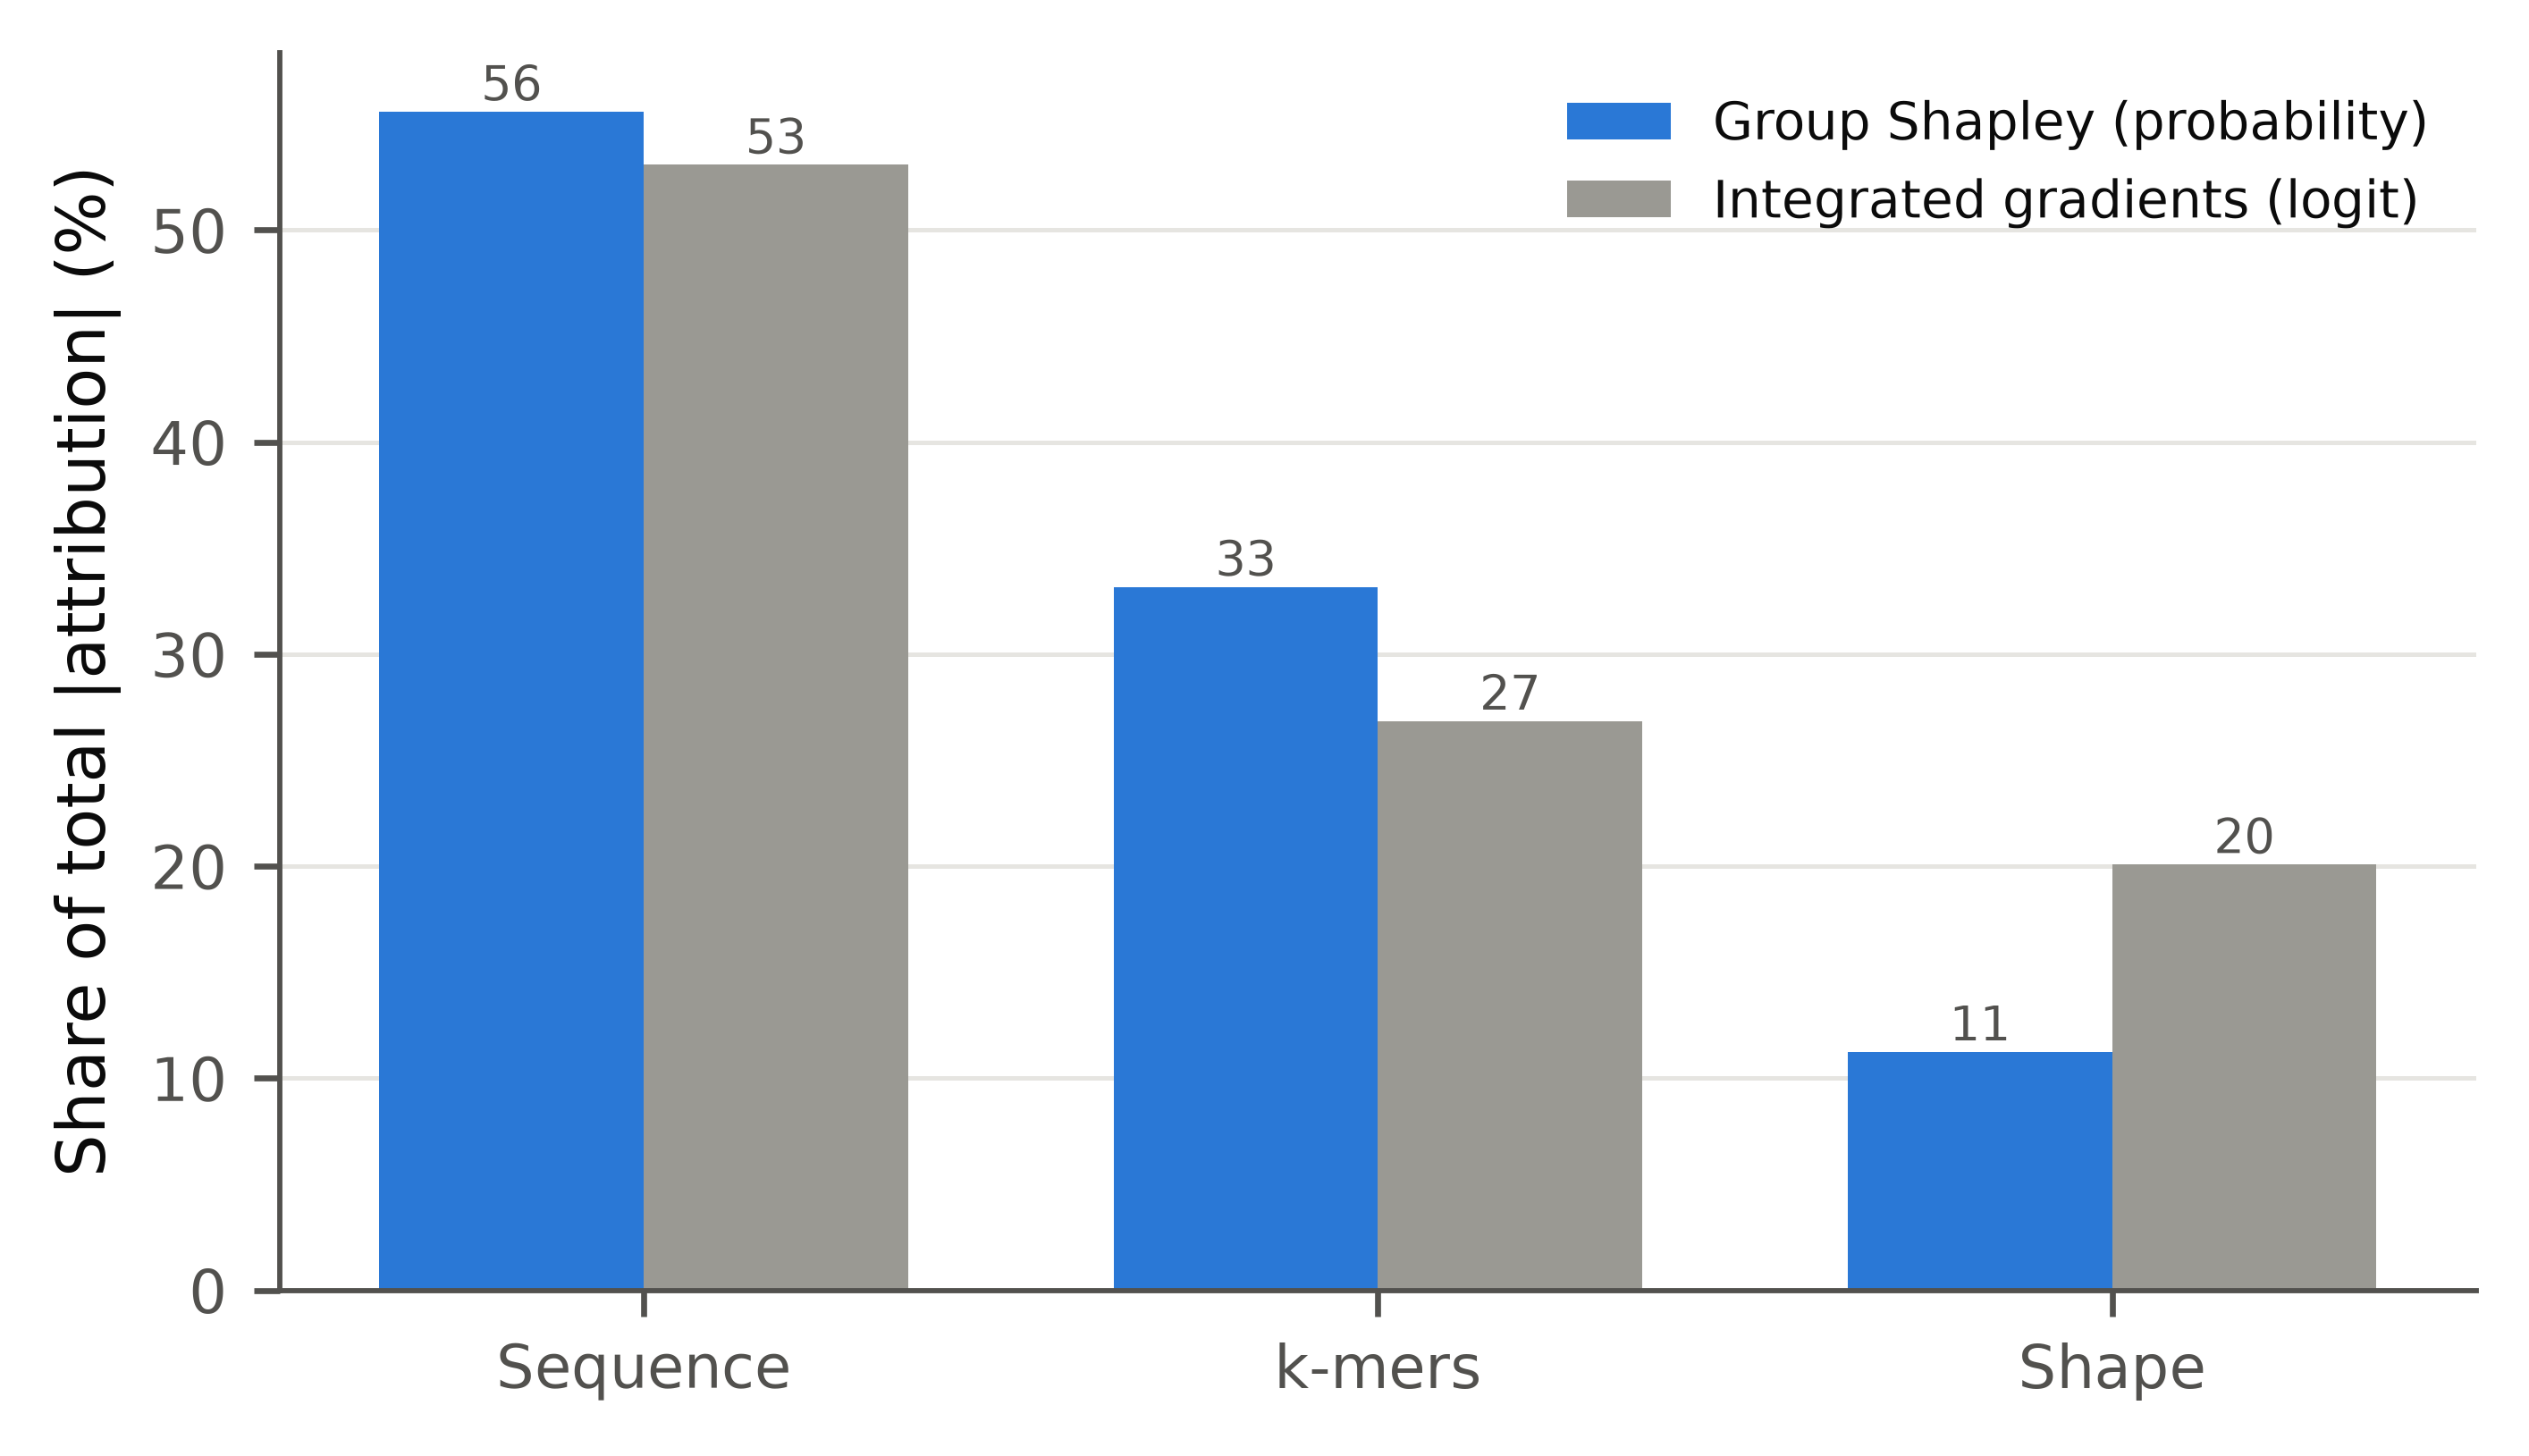

**ig_sequence_profile** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/ig_sequence_profile.png`  
Integrated-gradients attribution of the one-hot sequence per position (summed over the four bases), averaged over the explained test sequences of each class; forward and mapped reverse-complement views averaged; baseline: uniform base composition.

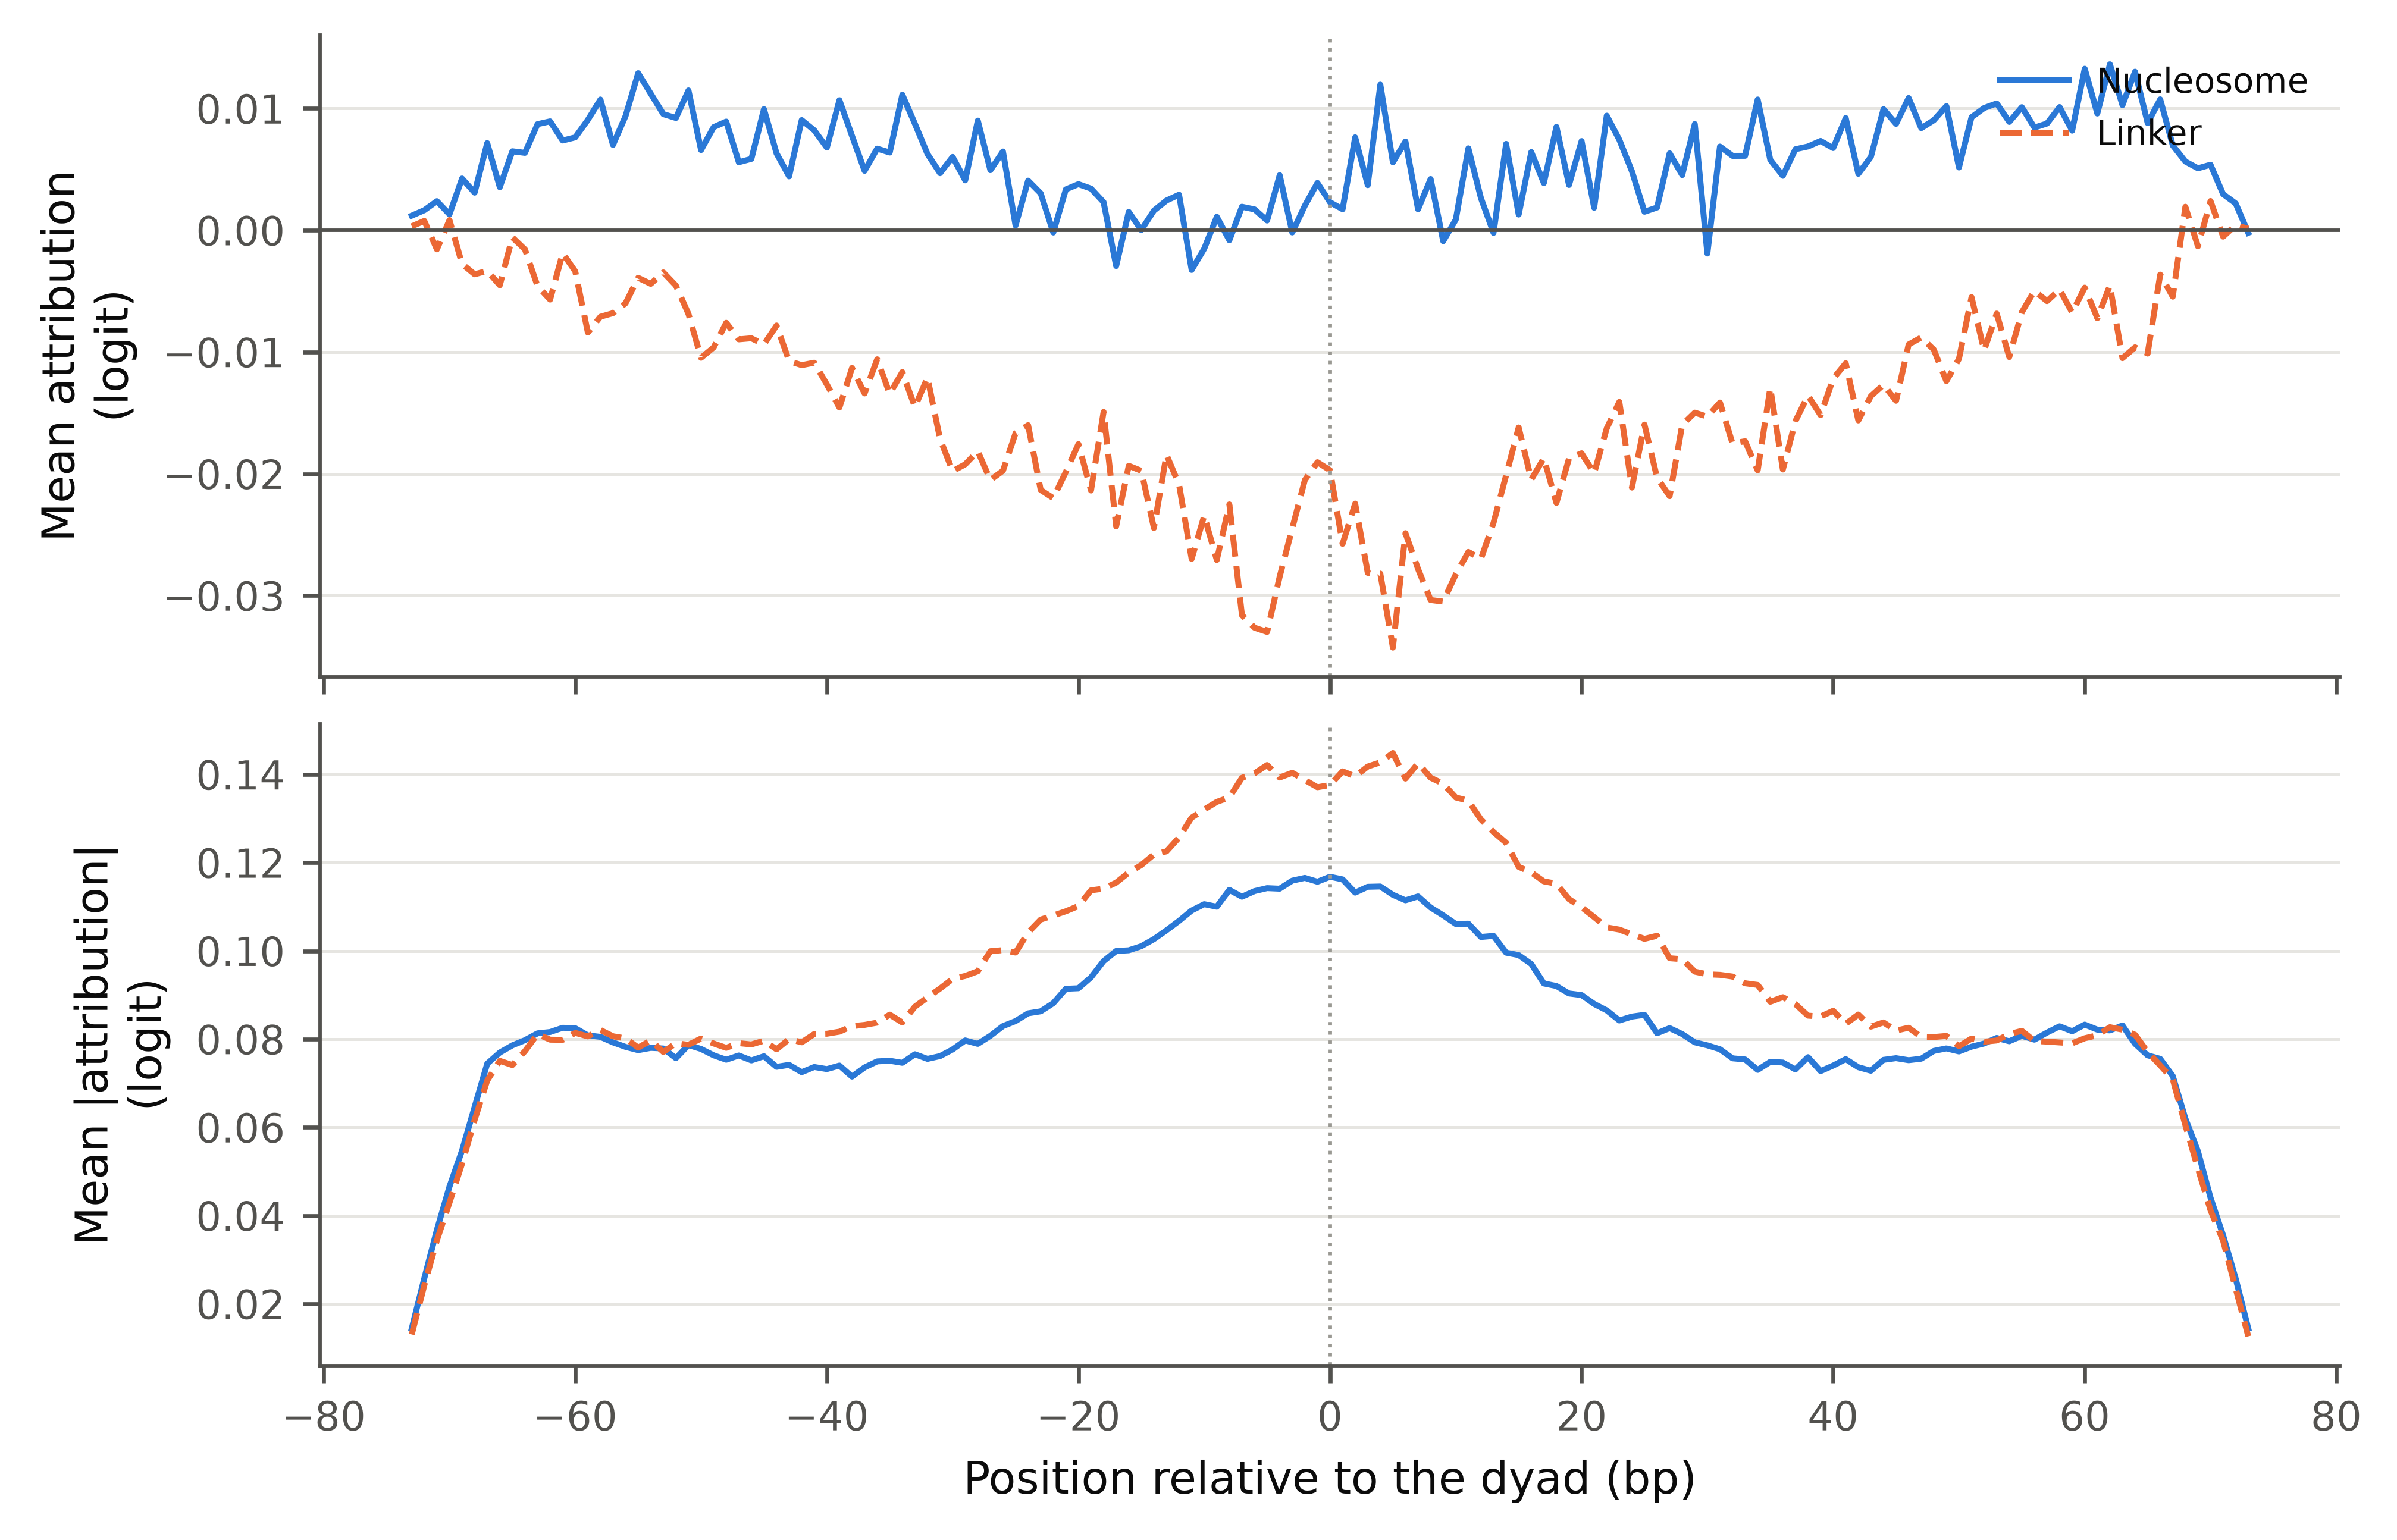

**ig_shape_profile** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/ig_shape_profile.png`  
Mean integrated-gradients attribution of each shape channel per position, by observed class (baseline: the training-row mean of each channel).

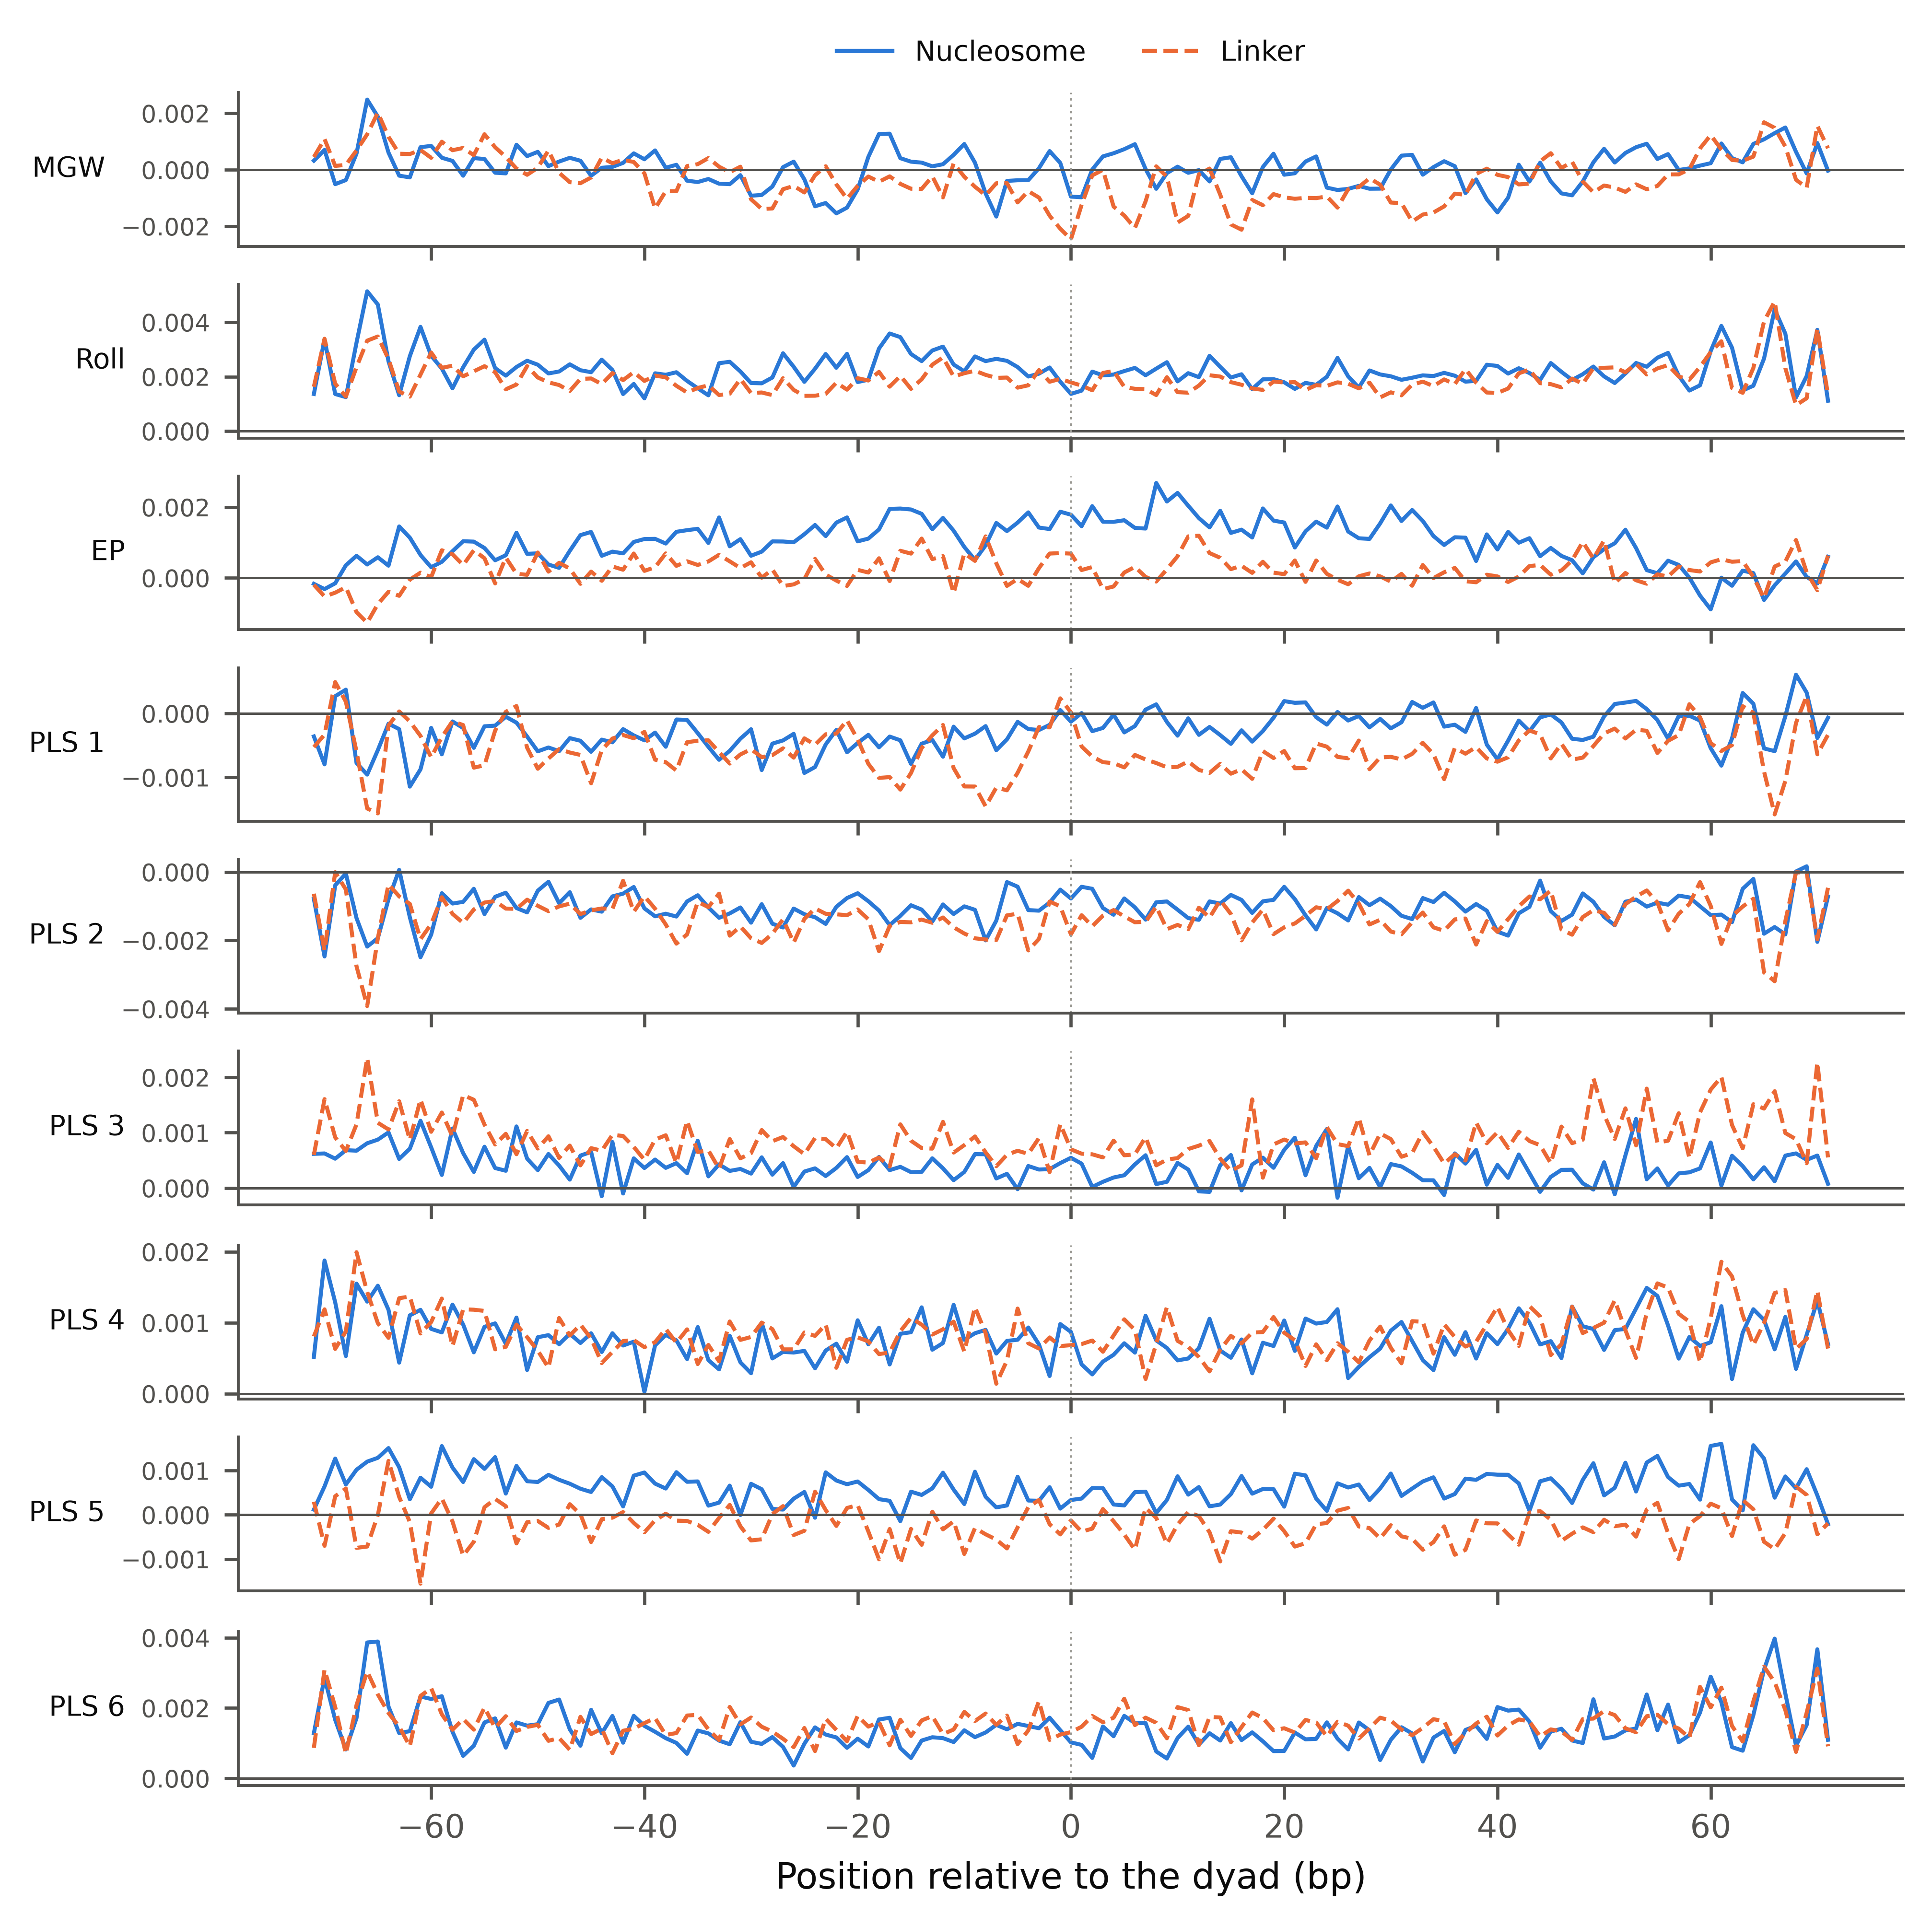

**ig_position_heatmap** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/ig_position_heatmap.png`  
Where along the 147 bp each input acts: mean absolute integrated-gradients attribution per position for the one-hot sequence and each shape channel, each row scaled to its own maximum (absolute values in the data file).

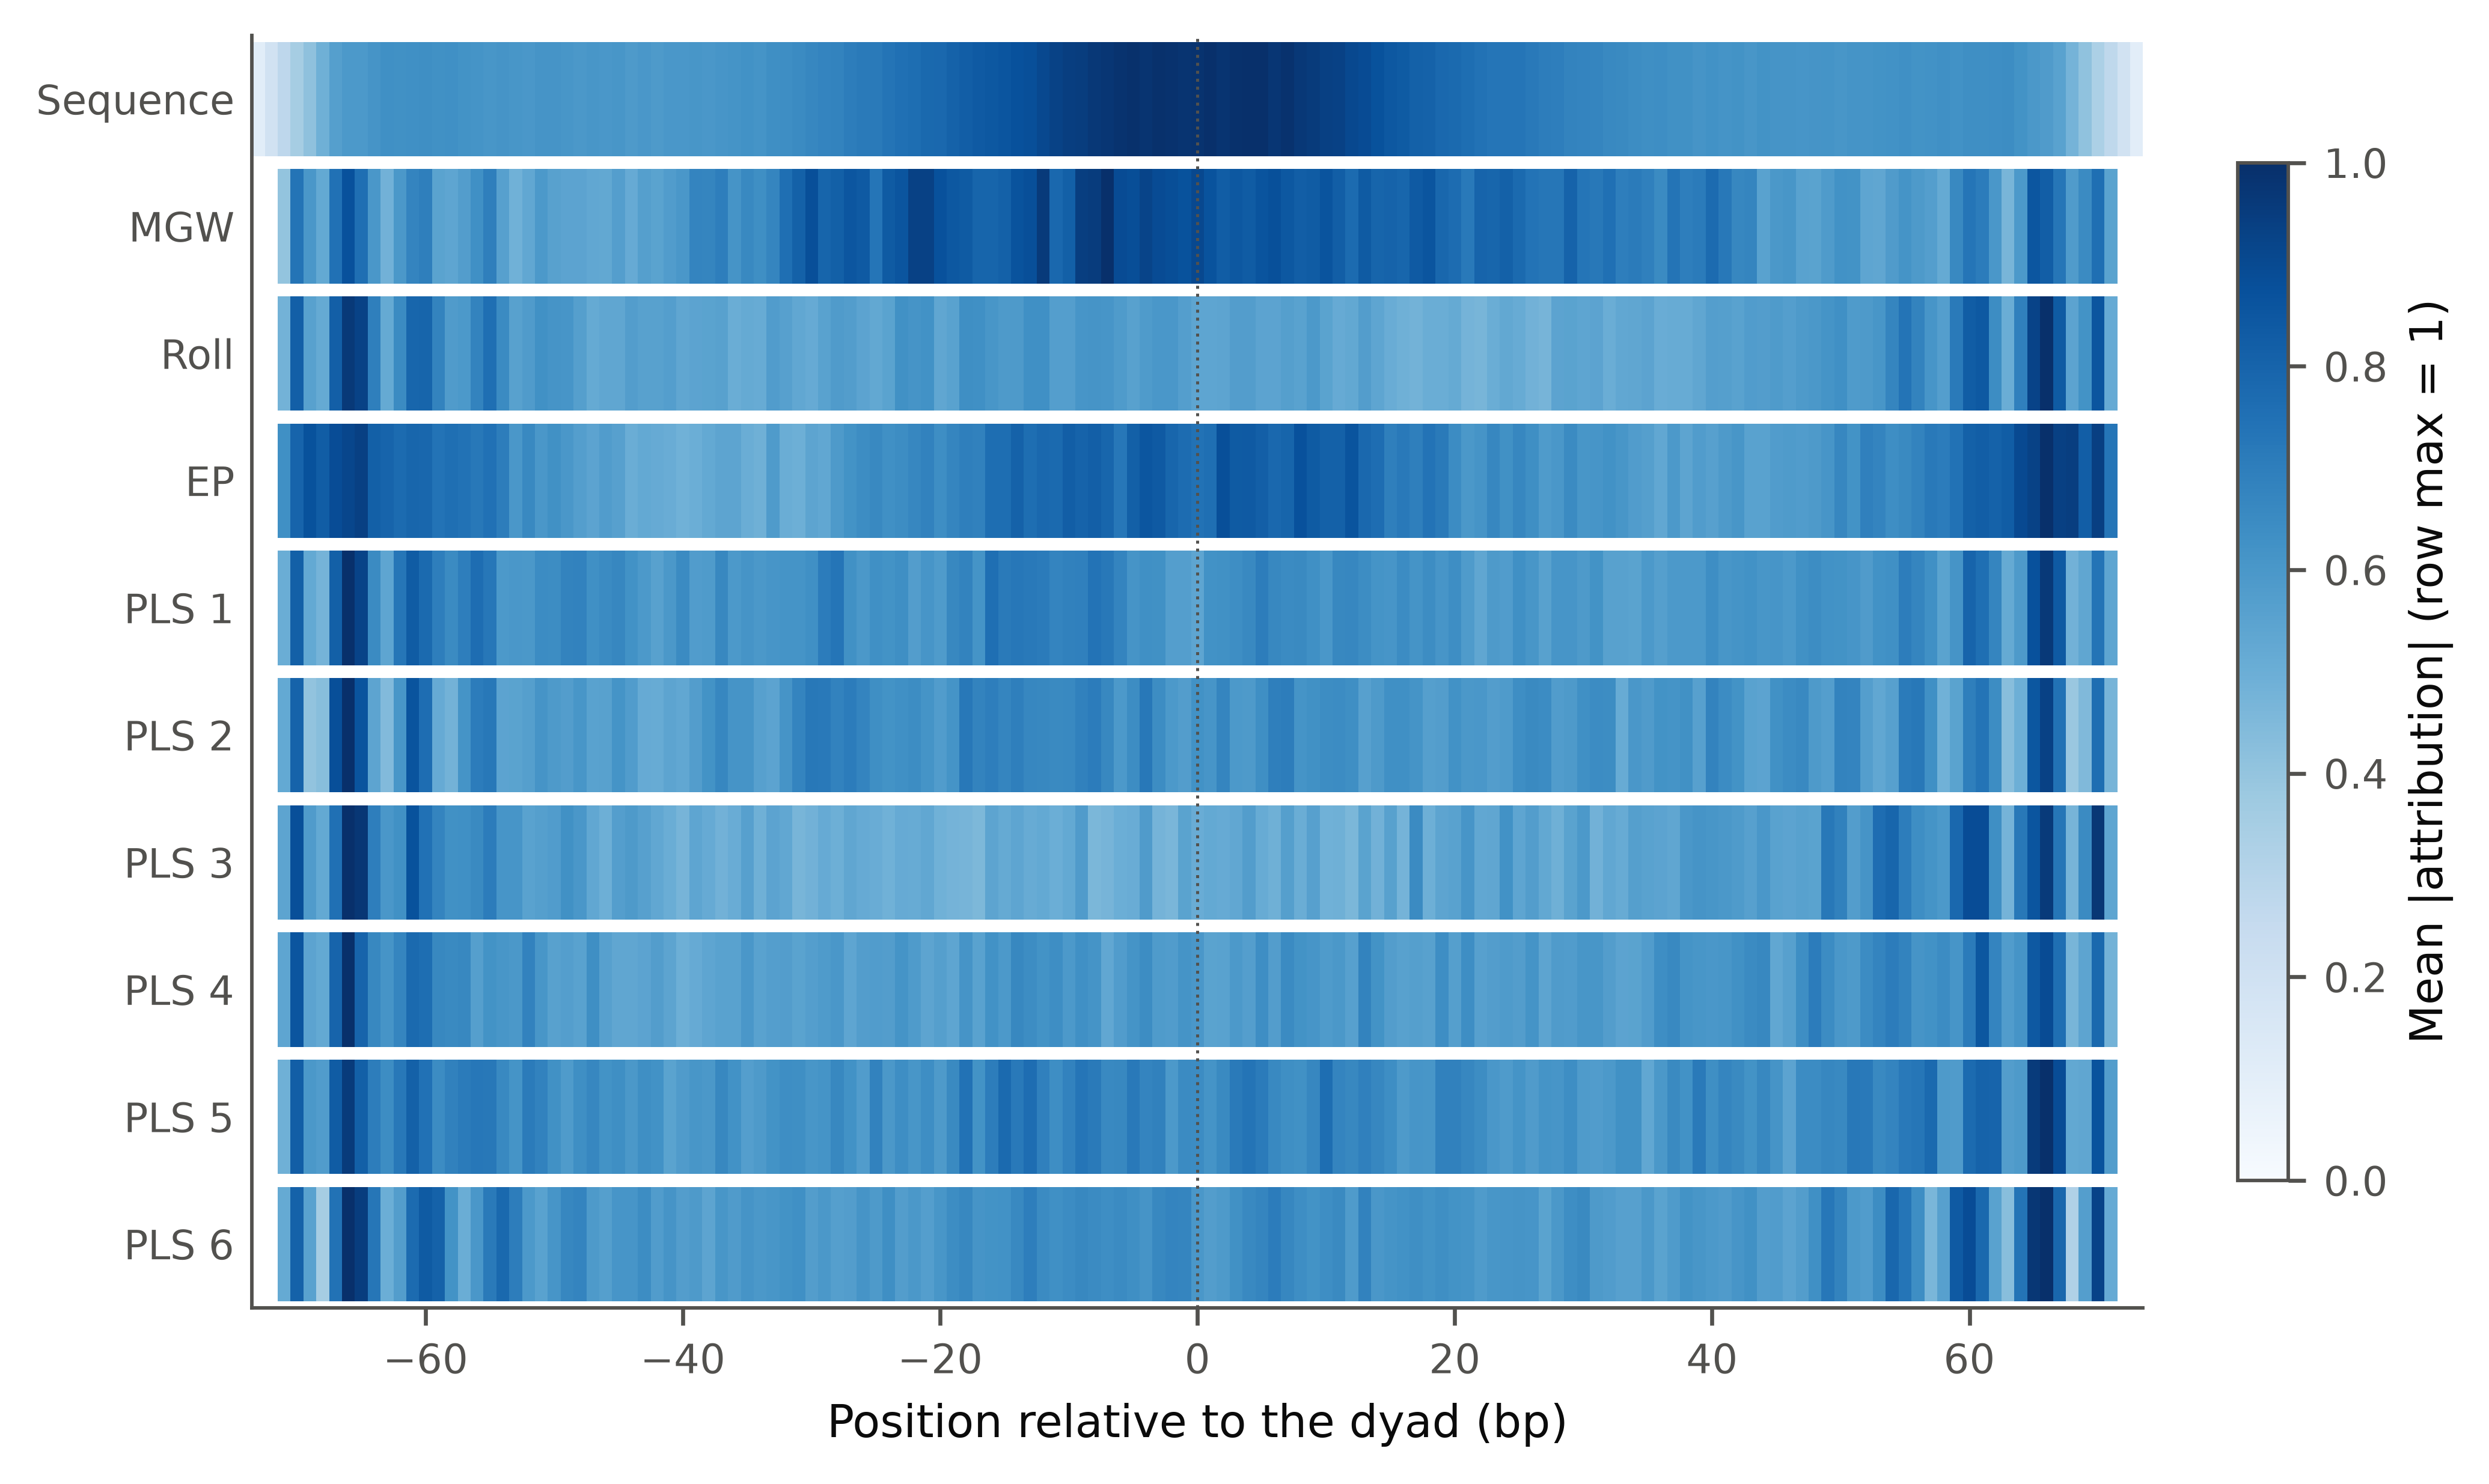

**pls_loadings** — `results/DatasetNup_1/Homo_sapiens/k5/full/explain/seed_151000/figures/pls_loadings.png`  
PLS rotation (z-scored track → component), mean over 5 fold(s) after aligning each component's sign; read the PLS players of the SHAP figures through these weights.

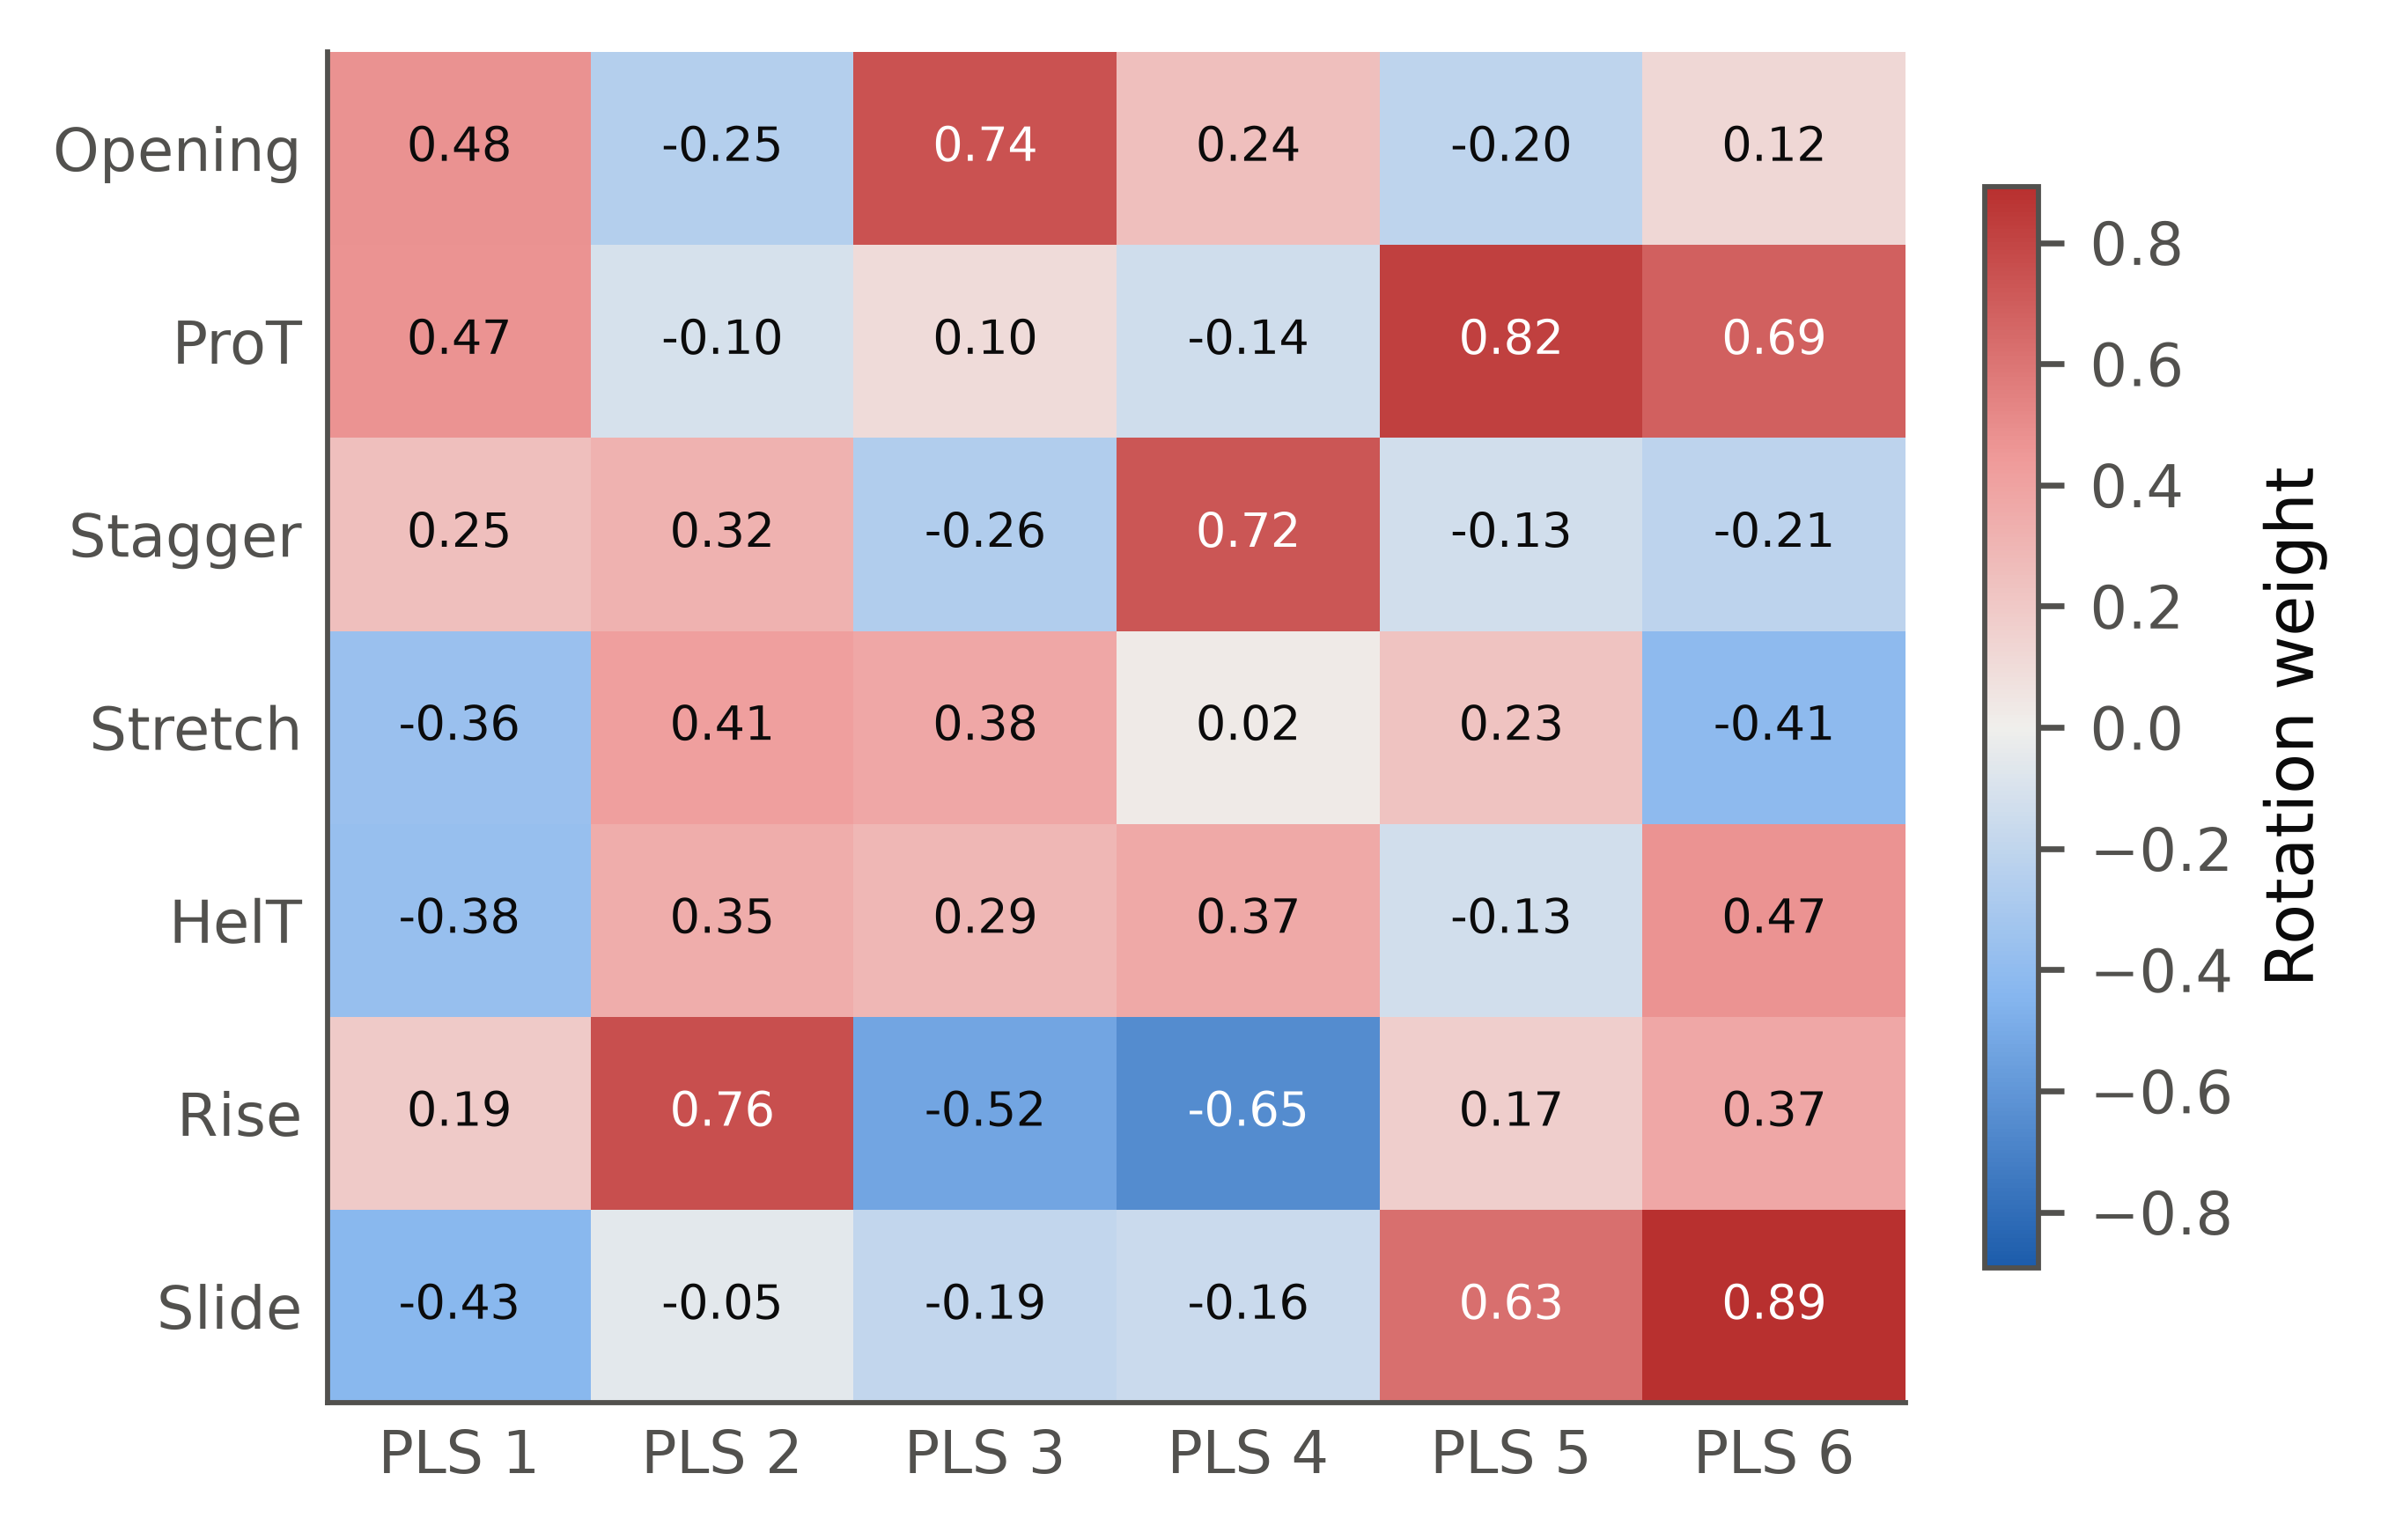

In [5]:
if (OUT / "figures").exists():
    for name in ("shap_overview", "shap_modality", "shap_tracks", "shap_channels", "shap_beeswarm_tracks",
                 "shap_beeswarm_channels", "shap_dependence_tracks", "shap_distribution_tracks", "shap_by_outcome_tracks",
                 "shap_interactions_tracks", "attribution_agreement", "ig_sequence_profile", "ig_shape_profile",
                 "ig_position_heatmap", "pls_loadings"):
        show(OUT / "figures" / f"{name}.png")
else:
    print("No figures yet: run the explanation (RUN_MODE = 'background').")